<a href="https://colab.research.google.com/github/DhimanTarafdar/dengue-virus-research/blob/main/Dengue_research_Part1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!pip install biopython mappy -q

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


In [2]:
import pandas as pd
from Bio import SeqIO

df = pd.read_csv("/content/DENGU-VIRUS-CSV.csv")

seqs = {}
for rec in SeqIO.parse("/content/DENGUE-VIRUS-sequences.fasta", "fasta"):
    acc = rec.id.split(".")[0]
    seqs[acc] = str(rec.seq).upper()

print(df.shape)
print(len(seqs))

(664, 15)
664


In [3]:
print(set(df["Accession"]) == set(seqs))

df["seq_len"] = df["Accession"].map(lambda a: len(seqs[a]))
print((df["seq_len"] != df["Length"]).sum())

True
0


In [4]:
def get_serotype(name):
    last = name.lower().split()[-1]
    mapping = {"1": "DENV-1", "i": "DENV-1", "2": "DENV-2", "3": "DENV-3", "4": "DENV-4"}
    return mapping[last]

df["ncbi_serotype"] = df["Organism_Name"].apply(get_serotype)
print(df["ncbi_serotype"].value_counts())

ncbi_serotype
DENV-3    310
DENV-2    278
DENV-1     73
DENV-4      3
Name: count, dtype: int64


In [5]:
df["year"] = df["Collection_Date"].astype(str).str.extract(r"(\d{4})")[0]
df["year"] = pd.to_numeric(df["year"])

print(df["year"].isna().sum())
print(df["year"].value_counts().sort_index())

14
year
2001.0      1
2002.0      4
2004.0      1
2005.0      1
2006.0     12
2007.0      4
2008.0      7
2009.0      6
2011.0      1
2017.0    136
2018.0     90
2019.0     70
2020.0      1
2021.0    101
2022.0     78
2023.0     79
2024.0     20
2025.0     38
Name: count, dtype: int64


In [6]:
print(pd.crosstab(df["year"], df["ncbi_serotype"]))

ncbi_serotype  DENV-1  DENV-2  DENV-3  DENV-4
year                                         
2001.0              0       0       1       0
2002.0              0       0       4       0
2004.0              0       1       0       0
2005.0              0       1       0       0
2006.0              0       2      10       0
2007.0              0       1       3       0
2008.0              0       3       4       0
2009.0              1       3       2       0
2011.0              0       1       0       0
2017.0             14     105      17       0
2018.0              5      49      36       0
2019.0              4       2      64       0
2020.0              1       0       0       0
2021.0             43       0      58       0
2022.0              0       2      76       0
2023.0              0      74       5       0
2024.0              0      14       5       1
2025.0              5      20      11       2


In [7]:
complete = df[df["Nuc_Completeness"] == "complete"]

for sero in ["DENV-1", "DENV-2", "DENV-3", "DENV-4"]:
    with open(f"/content/ref_{sero}.fa", "w") as f:
        for acc in complete[complete["ncbi_serotype"] == sero]["Accession"]:
            f.write(f">{acc}\n{seqs[acc]}\n")

print(complete["ncbi_serotype"].value_counts())

ncbi_serotype
DENV-3    37
DENV-2    22
DENV-1     7
DENV-4     2
Name: count, dtype: int64


In [8]:
import mappy as mp

aligners = {}
for sero in ["DENV-1", "DENV-2", "DENV-3", "DENV-4"]:
    aligners[sero] = mp.Aligner(f"/content/ref_{sero}.fa", preset="sr", k=9, w=3)

def best_match(acc):
    seq = seqs[acc]
    scores = {}
    for sero, aligner in aligners.items():
        best = 0
        for hit in aligner.map(seq):
            if hit.ctg == acc:
                continue
            if hit.mlen > best:
                best = hit.mlen
        scores[sero] = best / len(seq)
    return scores

rows = []
for acc in df["Accession"]:
    s = best_match(acc)
    top = max(s, key=s.get)
    rows.append([acc, top, s[top]])

result = pd.DataFrame(rows, columns=["Accession", "checked_serotype", "match_score"])
df = df.merge(result, on="Accession")
print(df.shape)

(664, 20)


In [9]:
print(pd.crosstab(df["ncbi_serotype"], df["checked_serotype"]))

wrong = df[df["ncbi_serotype"] != df["checked_serotype"]]
print(len(wrong))
print(wrong["year"].value_counts())
print(wrong["Genotype"].value_counts(dropna=False))

checked_serotype  DENV-1  DENV-2  DENV-3  DENV-4
ncbi_serotype                                   
DENV-1                29       0      44       0
DENV-2                 0     278       0       0
DENV-3                 0       0     310       0
DENV-4                 0       0       0       3
44
year
2021.0    43
2020.0     1
Name: count, dtype: int64
Genotype
1    44
Name: count, dtype: int64


In [10]:
df["serotype"] = df["checked_serotype"]
df["label_wrong"] = df["ncbi_serotype"] != df["serotype"]

print(df["serotype"].value_counts())
print(df["label_wrong"].sum())

serotype
DENV-3    354
DENV-2    278
DENV-1     29
DENV-4      3
Name: count, dtype: int64
44


In [11]:
print(pd.crosstab(df["year"], df["serotype"]))

serotype  DENV-1  DENV-2  DENV-3  DENV-4
year                                    
2001.0         0       0       1       0
2002.0         0       0       4       0
2004.0         0       1       0       0
2005.0         0       1       0       0
2006.0         0       2      10       0
2007.0         0       1       3       0
2008.0         0       3       4       0
2009.0         1       3       2       0
2011.0         0       1       0       0
2017.0        14     105      17       0
2018.0         5      49      36       0
2019.0         4       2      64       0
2020.0         0       0       1       0
2021.0         0       0     101       0
2022.0         0       2      76       0
2023.0         0      74       5       0
2024.0         0      14       5       1
2025.0         5      20      11       2


In [12]:
audit = pd.crosstab(df["ncbi_serotype"], df["serotype"])
audit.loc["Total"] = audit.sum()
print(audit)

print(df[df["label_wrong"]][["Accession", "Organism_Name", "Length", "year", "Submitters"]].head(10))

serotype       DENV-1  DENV-2  DENV-3  DENV-4
ncbi_serotype                                
DENV-1             29       0      44       0
DENV-2              0     278       0       0
DENV-3              0       0     310       0
DENV-4              0       0       0       3
Total              29     278     354       3
    Accession        Organism_Name  Length    year  \
356  OQ520872  dengue virus type 1     395  2021.0   
357  OQ520873  dengue virus type 1     414  2021.0   
358  OQ520874  dengue virus type 1     414  2021.0   
359  OQ520875  dengue virus type 1     430  2021.0   
360  OQ520876  dengue virus type 1     430  2021.0   
361  OQ519654  dengue virus type 1    1479  2021.0   
362  OQ519655  dengue virus type 1    1479  2021.0   
363  OQ519656  dengue virus type 1    1479  2021.0   
364  OQ519657  dengue virus type 1    1479  2021.0   
365  OQ519658  dengue virus type 1    1479  2021.0   

                                        Submitters  
356  Jahan,A., Shyamal,K., Aun

In [13]:
df.to_csv("/content/dengue_step1_serotype.csv", index=False)

In [14]:
def get_position(acc, sero):
    seq = seqs[acc]
    best = None
    for hit in aligners[sero].map(seq):
        if hit.ctg == acc:
            continue
        if best is None or hit.mlen > best.mlen:
            best = hit
    if best is None:
        return None, None
    return best.r_st, best.r_en

starts = []
ends = []
for acc, sero in zip(df["Accession"], df["serotype"]):
    s, e = get_position(acc, sero)
    starts.append(s)
    ends.append(e)

df["g_start"] = starts
df["g_end"] = ends
print(df["g_start"].isna().sum())

0


In [15]:
E_START = 935
E_END = 2420

def e_overlap(row):
    if pd.isna(row["g_start"]):
        return 0
    return max(0, min(row["g_end"], E_END) - max(row["g_start"], E_START))

df["e_overlap"] = df.apply(e_overlap, axis=1)
df["span"] = df["g_end"] - df["g_start"]

In [16]:
def get_region(row):
    if row["Length"] > 9000:
        return "complete genome"
    if pd.isna(row["span"]):
        return "unmapped"
    if row["e_overlap"] / row["span"] >= 0.8:
        return "E gene"
    if row["e_overlap"] >= 1000:
        return "long, contains E"
    return "not E"

df["region"] = df.apply(get_region, axis=1)
print(df["region"].value_counts())

region
E gene              316
not E               222
complete genome     102
long, contains E     24
Name: count, dtype: int64


In [17]:
df.to_csv("/content/dengue_step2_region.csv", index=False)

In [18]:
# fraction of bases that are not A, C, G, T
def n_fraction(acc):
    seq = seqs[acc]
    bad = sum(1 for base in seq if base not in "ACGT")
    return bad / len(seq)

df["n_frac"] = df["Accession"].apply(n_fraction)
df["many_n"] = df["n_frac"] > 0.01

df["seq"] = df["Accession"].map(seqs)
df["duplicate"] = df.duplicated(subset=["seq"], keep="first")

print(df["many_n"].sum())
print(df["duplicate"].sum())

27
198


In [19]:
df["no_year"] = df["year"].isna()
print(df["no_year"].sum())
print(df[df["no_year"]][["Accession", "serotype", "Collection_Date", "Submitters"]].head(14))

14
    Accession serotype Collection_Date  \
646  DQ401689   DENV-3             NaN   
647  DQ401691   DENV-3             NaN   
648  DQ401692   DENV-3             NaN   
649  DQ401693   DENV-3             NaN   
650  AY656669   DENV-3             NaN   
651  AY656670   DENV-3             NaN   
652  AY656671   DENV-3             NaN   
653  AY656672   DENV-3             NaN   
654  AY656673   DENV-3             NaN   
655  AY656674   DENV-3             NaN   
657  AY496872   DENV-3             NaN   
660  AY496875   DENV-3             NaN   
661  AY496876   DENV-3             NaN   
663  AY496878   DENV-3             NaN   

                                            Submitters  
646  Islam,M.A., Khan,A.H., Ahmed,M.U., Begum,N., C...  
647  Islam,M.A., Khan,A.H., Ahmed,M.U., Begum,N., C...  
648  Islam,M.A., Khan,A.H., Ahmed,M.U., Begum,N., C...  
649  Islam,M.A., Khan,A.H., Ahmed,M.U., Begum,N., C...  
650  Podder,G., Breiman,R.F., Azim,T., Thu,H.M., Ve...  
651  Podder,G., Breiman,

In [20]:
df["has_E"] = df["region"].isin(["E gene", "complete genome", "long, contains E"])

# E gene sequences that are shorter than 1400 are only partial E
df["partial_E"] = (df["region"] == "E gene") & (df["Length"] < 1400)

print(df["has_E"].sum())
print(df["partial_E"].sum())

442
1


In [21]:
E_all = df[df["has_E"]]
E_good = E_all[(~E_all["many_n"]) & (~E_all["no_year"]) & (~E_all["partial_E"])]
E_unique = E_good[~E_good["duplicate"]]

print("E-containing:", len(E_all))
print("after quality filter (for counting):", len(E_good))
print("after removing duplicates (for trees):", len(E_unique))

print(pd.crosstab(E_good["year"], E_good["serotype"]))
print(pd.crosstab(E_unique["year"], E_unique["serotype"]))

E-containing: 442
after quality filter (for counting): 400
after removing duplicates (for trees): 269
serotype  DENV-1  DENV-2  DENV-3  DENV-4
year                                    
2001.0         0       0       1       0
2002.0         0       0       4       0
2004.0         0       1       0       0
2005.0         0       1       0       0
2006.0         0       2      10       0
2007.0         0       1       3       0
2008.0         0       3       4       0
2009.0         1       3       2       0
2011.0         0       1       0       0
2017.0         7      54       8       0
2018.0         5      30      24       0
2019.0         4       1      49       0
2020.0         0       0       1       0
2021.0         0       0      96       0
2022.0         0       0      39       0
2023.0         0      16       1       0
2024.0         0      11       5       1
2025.0         0       6       5       0
serotype  DENV-1  DENV-2  DENV-3  DENV-4
year                                 

In [22]:
df.drop(columns=["seq"]).to_csv("/content/dengue_step3_flags.csv", index=False)

In [23]:
print(df[df["no_year"]][["Accession", "Isolate", "Release_Date", "Length"]])

    Accession          Isolate Release_Date  Length
646  DQ401689  mutant BDH02-01   2006-03-15   10707
647  DQ401691  mutant BDH02-03   2006-03-15   10707
648  DQ401692  mutant BDH02-04   2006-03-15   10707
649  DQ401693  mutant BDH02-07   2006-03-15   10707
650  AY656669              114   2005-11-26    1479
651  AY656670              164   2005-11-26    1479
652  AY656671              165   2005-11-26    1479
653  AY656672              Apu   2005-11-26    1479
654  AY656673            Jacob   2005-11-26    1479
655  AY656674              058   2005-11-26    1479
657  AY496872          BDH02-2   2005-03-05    3033
660  AY496875          BDH02-5   2005-03-05    3033
661  AY496876          BDH02-6   2005-03-05    3033
663  AY496878          BDH02-8   2005-03-05    3033


In [24]:
print(pd.crosstab(df["year"], df["many_n"]))
print(df[df["many_n"]][["Accession", "year", "serotype", "Length", "n_frac"]].sort_values("year").head(15))

many_n  False  True 
year                
2001.0      1      0
2002.0      4      0
2004.0      1      0
2005.0      1      0
2006.0     12      0
2007.0      4      0
2008.0      7      0
2009.0      6      0
2011.0      1      0
2017.0    136      0
2018.0     90      0
2019.0     70      0
2020.0      1      0
2021.0    101      0
2022.0     78      0
2023.0     79      0
2024.0     20      0
2025.0     11     27
   Accession    year serotype  Length    n_frac
0   OZ484492  2025.0   DENV-2   10512  0.024068
1   OZ484493  2025.0   DENV-3   10461  0.140618
2   OZ484494  2025.0   DENV-2   10512  0.152778
3   OZ484495  2025.0   DENV-2   10512  0.063927
4   OZ484496  2025.0   DENV-2   10512  0.041096
5   OZ484497  2025.0   DENV-2   10512  0.115963
6   OZ484498  2025.0   DENV-2   10512  0.099981
7   OZ484499  2025.0   DENV-2   10512  0.082097
8   OZ484500  2025.0   DENV-3   10461  0.091100
9   OZ484501  2025.0   DENV-1   10477  0.136585
10  OZ484502  2025.0   DENV-1   10477  0.050014
11  

In [25]:
E_all = df[df["has_E"]]

E_count = E_all[(~E_all["many_n"]) & (~E_all["no_year"]) & (~E_all["partial_E"])]
E_tree = E_all[(~E_all["many_n"]) & (~E_all["partial_E"]) & (~E_all["duplicate"])]

print("for counting:", len(E_count))
print("for trees:", len(E_tree))
print(E_tree["serotype"].value_counts())

for counting: 400
for trees: 282
serotype
DENV-3    163
DENV-2    103
DENV-1     15
DENV-4      1
Name: count, dtype: int64


In [26]:
df["year_note"] = ""
mask = df["Isolate"].astype(str).str.contains("BDH02") & df["year"].isna()
df.loc[mask, "year"] = 2002
df.loc[mask, "year_note"] = "from isolate name, to verify"

print(mask.sum())
print(df["year"].isna().sum())

8
6


In [27]:
e_ref = {}
for sero in ["DENV-1", "DENV-2", "DENV-3"]:
    pool = df[(df["serotype"] == sero) & (df["region"] == "E gene") & (df["Length"].isin([1479, 1485]))]
    best = pool.sort_values("n_frac").iloc[0]["Accession"]
    e_ref[sero] = best
    with open(f"/content/Eref_{sero}.fa", "w") as f:
        f.write(f">{best}\n{seqs[best]}\n")

print(e_ref)

{'DENV-1': 'OQ826841', 'DENV-2': 'PZ017579', 'DENV-3': 'PZ017435'}


In [28]:
e_aligners = {}
for sero in e_ref:
    e_aligners[sero] = mp.Aligner(f"/content/Eref_{sero}.fa", preset="map-ont")

e_seq = {}
for acc, sero, has_e in zip(df["Accession"], df["serotype"], df["has_E"]):
    if (not has_e) or (sero not in e_aligners):
        continue
    hits = list(e_aligners[sero].map(seqs[acc]))
    if len(hits) == 0:
        continue
    best = max(hits, key=lambda h: h.mlen)
    e_seq[acc] = seqs[acc][best.q_st:best.q_en]

df["E_seq"] = df["Accession"].map(e_seq)
df["E_len"] = df["E_seq"].str.len()

print(df["E_seq"].notna().sum())
print(df["E_len"].value_counts().head(8))

439
E_len
1479.0    262
1485.0    144
1484.0     19
1478.0      7
1442.0      2
1406.0      2
847.0       1
1443.0      1
Name: count, dtype: int64


In [29]:
def n_fraction_E(s):
    if not isinstance(s, str):
        return None
    return sum(1 for b in s if b not in "ACGT") / len(s)

df["E_n_frac"] = df["E_seq"].apply(n_fraction_E)
df["E_ok"] = (df["E_len"] >= 1400) & (df["E_n_frac"] <= 0.01)

print(df["E_ok"].sum())
print(df[df["has_E"] & ~df["E_ok"]][["Accession", "serotype", "region", "Length", "E_len", "E_n_frac"]])

430
    Accession serotype           region  Length   E_len  E_n_frac
1    OZ484493   DENV-3  complete genome   10461  1479.0  0.133198
8    OZ484500   DENV-3  complete genome   10461  1479.0  0.133198
9    OZ484501   DENV-1  complete genome   10477  1485.0  0.158249
11   OZ484503   DENV-4  complete genome   10511     NaN       NaN
12   OZ484504   DENV-4  complete genome   10511     NaN       NaN
14   OZ484506   DENV-1  complete genome   10477  1484.0  0.158356
21   OZ484513   DENV-3  complete genome   10461   847.0  0.232586
23   OZ484515   DENV-3  complete genome   10461  1479.0  0.150101
24   OZ484516   DENV-3  complete genome   10461  1479.0  0.133198
25   OZ484517   DENV-3  complete genome   10461  1479.0  0.302231
37   PZ017578   DENV-4           E gene    1584     NaN       NaN
117  PP697469   DENV-2           E gene     684   568.0  0.000000


In [30]:
E_count = df[df["E_ok"] & df["year"].notna()]
E_tree = df[df["E_ok"]].drop_duplicates(subset="E_seq")

print(len(E_count), len(E_tree))
print(E_tree["serotype"].value_counts())
print(pd.crosstab(E_count["year"], E_count["serotype"]))

424 252
serotype
DENV-3    136
DENV-2     99
DENV-1     17
Name: count, dtype: int64
serotype  DENV-1  DENV-2  DENV-3
year                            
2001.0         0       0       1
2002.0         0       0      12
2004.0         0       1       0
2005.0         0       1       0
2006.0         0       2      10
2007.0         0       1       3
2008.0         0       3       4
2009.0         1       3       2
2011.0         0       1       0
2017.0         7      54       8
2018.0         5      30      24
2019.0         4       1      49
2020.0         0       0       1
2021.0         0       0      96
2022.0         0       0      39
2023.0         0      16       1
2024.0         0      11       5
2025.0         3      20       5


In [31]:
with open("/content/E_tree.fasta", "w") as f:
    for _, r in E_tree.iterrows():
        f.write(f">{r['Accession']}|{r['serotype']}|{r['year']}\n{r['E_seq']}\n")

df.drop(columns=["seq", "E_seq"]).to_csv("/content/dengue_step4_E.csv", index=False)
E_tree.drop(columns=["seq", "E_seq"]).to_csv("/content/E_tree_info.csv", index=False)

In [32]:
d2 = df[df["serotype"] == "DENV-2"]
print(pd.crosstab(d2["year"], d2["region"]))

not_e = df[df["region"] == "not E"]
print(pd.crosstab(not_e["year"], not_e["Length"]))

region  E gene  complete genome  long, contains E  not E
year                                                    
2004.0       1                0                 0      0
2005.0       1                0                 0      0
2006.0       2                0                 0      0
2007.0       1                0                 0      0
2008.0       3                0                 0      0
2009.0       3                0                 0      0
2011.0       1                0                 0      0
2017.0      47                7                 0     51
2018.0      30                0                 0     19
2019.0       0                1                 0      1
2022.0       0                0                 0      2
2023.0       3                1                13     57
2024.0      10                1                 0      3
2025.0       6               14                 0      0
Length  150   151   208   232   260   341   352   353   372   383   ...  449   \
year   

In [33]:
!pip install zstandard -q

import io
import urllib.request
import zstandard

def load_metadata(url):
    data = urllib.request.urlopen(url).read()
    text = zstandard.ZstdDecompressor().decompressobj().decompress(data)
    return pd.read_csv(io.BytesIO(text), sep="\t", low_memory=False)

meta = {}
for s in ["denv1", "denv2", "denv3"]:
    url = f"https://data.nextstrain.org/files/workflows/dengue/metadata_{s}.tsv.zst"
    meta[s] = load_metadata(url)
    print(s, meta[s].shape)

print(meta["denv3"].columns.tolist())
print(meta["denv3"].head(3).T)

denv1 (21928, 39)
denv2 (20391, 39)
denv3 (10008, 39)
['accession', 'strain', 'accession_version', 'date', 'region', 'country', 'division', 'location', 'length', 'host', 'host_genus', 'host_type', 'is_lab_host', 'date_released', 'date_updated', 'authors', 'full_authors', 'institution', 'serotype_genbank', 'url', 'genotype_nextclade', 'alignmentStart', 'alignmentEnd', 'genome_coverage', 'failedCdses', 'E_coverage', 'C_coverage', 'prM_coverage', 'NS1_coverage', 'NS2A_coverage', 'NS2B_coverage', 'NS3_coverage', 'NS4A_coverage', '2K_coverage', 'NS4B_coverage', 'NS5_coverage', 'genotype', 'major_lineage', 'minor_lineage']
                                                                    0  \
accession                                                    PV554919   
strain                                             AIIMSR-DEN-49/2024   
accession_version                                          PV554919.1   
date                                                       2024-08-30   
region    

In [34]:
for s in meta:
    m = meta[s]
    found = m.astype(str).apply(lambda col: col.str.contains("Bangladesh", case=False)).any(axis=1)
    print(s, found.sum())

denv1 33
denv2 278
denv3 355


In [35]:
short = df[df["Length"] <= 160]
print(short[["Accession", "serotype", "year", "Isolate", "Submitters"]].head(8))
print(short["Submitters"].str[:40].value_counts())

   Accession serotype    year     Isolate  \
55  PQ621312   DENV-2  2023.0  S20/DENV-2   
56  PQ621313   DENV-2  2023.0  S18/DENV-2   
57  PQ621314   DENV-2  2023.0  S16/DENV-2   
58  PQ621315   DENV-2  2023.0  S15/DENV-2   
59  PQ621316   DENV-2  2023.0  S14/DENV-2   
60  PQ621317   DENV-2  2023.0  S13/DENV-2   
61  PQ621318   DENV-2  2023.0  S12/DENV-2   
62  PQ621319   DENV-2  2023.0  S11/DENV-2   

                                           Submitters  
55  Akter,L., Rakib,T.M., Rana,E.A., Alam,M., Khal...  
56  Akter,L., Rakib,T.M., Rana,E.A., Alam,M., Khal...  
57  Akter,L., Rakib,T.M., Rana,E.A., Alam,M., Khal...  
58  Akter,L., Rakib,T.M., Rana,E.A., Alam,M., Khal...  
59  Akter,L., Rakib,T.M., Rana,E.A., Alam,M., Khal...  
60  Akter,L., Rakib,T.M., Rana,E.A., Alam,M., Khal...  
61  Akter,L., Rakib,T.M., Rana,E.A., Alam,M., Khal...  
62  Akter,L., Rakib,T.M., Rana,E.A., Alam,M., Khal...  
Submitters
Akter,L., Rakib,T.M., Rana,E.A., Alam,M.    42
Name: count, dtype: int64


In [36]:
all_meta = pd.concat([
    meta["denv1"].assign(file="denv1"),
    meta["denv2"].assign(file="denv2"),
    meta["denv3"].assign(file="denv3"),
])

wrong_acc = df[df["label_wrong"]]["Accession"]
x = all_meta[all_meta["accession"].isin(wrong_acc)]

print(len(x))
print(x["file"].value_counts())
print(x["serotype_genbank"].value_counts())
print(x["genotype"].value_counts(dropna=False))

44
file
denv3    44
Name: count, dtype: int64
serotype_genbank
denv3    44
Name: count, dtype: int64
genotype
3I    44
Name: count, dtype: int64


In [37]:
ns = all_meta[["accession", "file", "genotype", "major_lineage", "minor_lineage", "E_coverage"]]
ns = ns.drop_duplicates("accession")
ns = ns.rename(columns={
    "accession": "Accession",
    "file": "ns_file",
    "genotype": "ns_genotype",
    "major_lineage": "ns_major",
    "minor_lineage": "ns_minor",
})

df = df.merge(ns, on="Accession", how="left")

print(df["ns_genotype"].notna().sum())
print(pd.crosstab(df["serotype"], df["ns_genotype"].fillna("none")))

661
ns_genotype  1I  1III  2II  2V   3I  3II  3III  none
serotype                                            
DENV-1        5    24    0   0    0    0     0     0
DENV-2        0     0  238  40    0    0     0     0
DENV-3        0     0    0   0  297   38    19     0
DENV-4        0     0    0   0    0    0     0     3


In [38]:
df["len_group"] = pd.cut(df["Length"], [0, 160, 600, 1200, 1600, 20000],
                         labels=["150", "160-600", "600-1200", "1200-1600", ">1600"])

print(pd.crosstab([df["serotype"], df["ns_genotype"]], df["len_group"]))

len_group             150  160-600  600-1200  1200-1600  >1600
serotype ns_genotype                                          
DENV-1   1I             0        0         0          0      5
         1III           0        0         7         15      2
DENV-2   2II            3       40        52         95     48
         2V            39        0         0          0      1
DENV-3   3I             0       74         7        166     50
         3II            0        0         0         26     12
         3III           0        1         0          0     18


In [39]:
good = df[df["Length"] >= 400]

for sero in ["DENV-1", "DENV-2", "DENV-3"]:
    sub = good[good["serotype"] == sero]
    print(sero)
    print(pd.crosstab(sub["year"], sub["ns_genotype"]))
    print()

DENV-1
ns_genotype  1I  1III
year                 
2009.0        0     1
2017.0        0    14
2018.0        0     5
2019.0        0     4
2025.0        5     0

DENV-2
ns_genotype  2II  2V
year                
2004.0         1   0
2005.0         1   0
2006.0         2   0
2007.0         1   0
2008.0         3   0
2009.0         3   0
2011.0         1   0
2017.0       105   0
2018.0        43   0
2019.0         2   0
2022.0         2   0
2023.0        30   1
2024.0        14   0
2025.0        20   0

DENV-3
ns_genotype  3I  3II  3III
year                      
2001.0        0    1     0
2002.0        0   12     0
2006.0        0   10     0
2007.0        0    3     0
2008.0        0    4     0
2009.0        0    2     0
2017.0       15    0     0
2018.0       35    0     0
2019.0       63    0     1
2020.0        1    0     0
2021.0       82    0    18
2022.0       72    0     0
2023.0        1    0     0
2024.0        5    0     0
2025.0       11    0     0



In [40]:
print(df[(df["ns_genotype"] == "2V") & (df["Length"] > 160)][["Accession", "year", "Length", "n_frac", "Submitters"]])

g3 = df[df["ns_genotype"] == "3III"]
print(g3[["Accession", "year", "Length", "Isolate"]].head(20))
print(g3["Submitters"].str[:40].value_counts())

   Accession    year  Length  n_frac  \
98  PQ657766  2023.0   10723     0.0   

                                           Submitters  
98  Mannan,A., Rob,M.A., Satter,M., Faisal,A., Cho...  
    Accession    year  Length   Isolate
378  ON103302  2021.0   10707       NaN
380  ON103390  2021.0   10707       NaN
382  ON111445  2021.0   10707       NaN
384  ON115021  2021.0   10707       NaN
386  ON115023  2021.0   10707       NaN
388  ON115025  2021.0   10707       NaN
390  ON115029  2021.0   10707       NaN
392  ON115182  2021.0   10707       NaN
394  ON115811  2021.0   10707       NaN
396  ON115814  2021.0   10707       NaN
398  ON115816  2021.0   10707       NaN
400  ON115818  2021.0   10707       NaN
402  ON116129  2021.0   10707       NaN
404  ON127418  2021.0   10707       NaN
406  ON127533  2021.0   10707       NaN
408  ON127537  2021.0   10707       NaN
410  ON127550  2021.0   10707       NaN
412  ON127552  2021.0   10707       NaN
443  MW599417  2019.0     444  Khulna02
Submitt

In [41]:
df["geno_ok"] = df["Length"] >= 400
print(df["geno_ok"].sum())

603


In [42]:
good = df[df["geno_ok"]]

for sero in ["DENV-2", "DENV-3"]:
    sub = good[good["serotype"] == sero]
    print(sero)
    print(pd.crosstab(sub["ns_minor"], sub["year"]))
    print()

DENV-2
year         2004.0  2005.0  2006.0  2007.0  2008.0  2009.0  2011.0  2017.0  \
ns_minor                                                                      
2II_A.1           1       1       2       1       3       3       1       0   
2II_A.2.1         0       0       0       0       0       0       0       8   
2II_F.1.1         0       0       0       0       0       0       0       0   
2II_F.1.1.2       0       0       0       0       0       0       0      97   
2II_F.1.2         0       0       0       0       0       0       0       0   
2V_F              0       0       0       0       0       0       0       0   

year         2018.0  2019.0  2022.0  2023.0  2024.0  2025.0  
ns_minor                                                     
2II_A.1           0       0       0       0       0       0  
2II_A.2.1         0       0       0       0       0       0  
2II_F.1.1         0       0       0      30      14      20  
2II_F.1.1.2      43       2       0       0       

In [43]:
df.drop(columns=["seq", "E_seq"]).to_csv("/content/dengue_step5_genotype.csv", index=False)

In [44]:
df["same_count"] = df.groupby("seq")["Accession"].transform("size")
df["suspect_template"] = (df["Length"] > 9000) & (df["same_count"] >= 10)
print(df["suspect_template"].sum())

rows = []
for acc in df[df["suspect_template"]]["Accession"]:
    partner = acc[:2] + str(int(acc[2:]) + 1)
    p = df[df["Accession"] == partner]
    if len(p) > 0:
        rows.append([acc, partner, p["Organism_Name"].iloc[0], p["ns_genotype"].iloc[0], p["Length"].iloc[0]])

print(pd.DataFrame(rows, columns=["suspect", "partner", "partner_organism", "partner_genotype", "partner_length"]))

18
     suspect   partner     partner_organism partner_genotype  partner_length
0   ON103302  ON103303  dengue virus type 1               3I           10661
1   ON103390  ON103391  dengue virus type 1               3I           10668
2   ON111445  ON111446  dengue virus type 1               3I           10651
3   ON115021  ON115022  dengue virus type 1               3I           10652
4   ON115023  ON115024  dengue virus type 1               3I           10652
5   ON115025  ON115026  dengue virus type 1               3I           10649
6   ON115029  ON115030  dengue virus type 1               3I           10669
7   ON115182  ON115183  dengue virus type 1               3I           10667
8   ON115811  ON115812  dengue virus type 1               3I           10637
9   ON115814  ON115815  dengue virus type 1               3I           10663
10  ON115816  ON115817  dengue virus type 1               3I           10354
11  ON115818  ON115819  dengue virus type 1               3I           10

In [45]:
d21 = df[(df["year"] == 2021) & (df["serotype"] == "DENV-3")]
print(len(d21), (~d21["suspect_template"]).sum())

101 83


In [46]:
acc = "PQ657766"
print(">" + acc)
print(df[df["Accession"] == acc]["E_seq"].iloc[0])

>PQ657766
ATGCGTTGTATAGGAATATCAAATAGAGACTTTGTGGAAGGGGTTTCAGGAGGAAGCTGGGTTGACATAGTCCTGGAACATGGAAGCTGTGTGACGACGATGGCAAAAAATAAACCAACATTGGATTTTGAACTGATAAAAACAGAAGCCAAACAGCCTGCCACCCTAAGGAAGTACTGTATAGAGGCAAAGCTAACCAACACAACAACAGAATCTCGCTGCCCAACACAAGGGGAACCCAGCCTAAATGAAGAGCAGGACAAAAGGTTCGTCTGCAAACACTCCATGGTAGACAGAGGATGGGGAAATGGATGTGGACTATTTGGAAAGGGAGGCATTGTGACCTGTGCTATGTTCAGATGCAAAAAGAACATGGAAGGAAAAGTTGTGCAACCAGAAAACTTGGAATACACCATTGTGATAACACCTCACTCAGGGGAAGAGCATGCAGTCGGAAATGACACAGGAAAACATGGCAAGGAAATCAAAATAACACCACAGAGTTCCATCACAGAAGCAGAATTGACAGGTTATGGCACTGTCACAATGGAGTGCTCTCCAAGAACGGGCCTCGACTTCAATGAGATGGTGTTGCTGCAGATGGAAAATAAAGCTTGGCTGGTGCACAGGCAATGGTTCCTAGACCTGCCGTTACCATGGTTGCCCGGAGCGGACACACAAGGGTCAAATTGGATACAGAAAGAGACATTGGTCACTTTCAAAAATCCCCATGCGAAGAAACAGGATGTTGTTGTTTTAGGATCCCAAGAAGGGGCCATGCACACAGCACTTACAGGGGCCACAGAAATCCAAATGTCATCAGGAAACTTACTCTTCACAGGACATCTCAAGTGCAGGCTGAGAATGGACAAGCTACAGCTCAAAGGAATGTCATACTCTATGTGCACAGGAAAGTTTAAAGTTGTGAAGGAAATAGCAGAAACACAACATGGAACAATAGTTATCAGAGTGCAATATGAAGGGGACGGC

In [47]:
df.drop(columns=["seq", "E_seq"]).to_csv("/content/dengue_step6_flags.csv", index=False)

In [48]:
df["use_main"] = df["E_ok"] & (~df["suspect_template"])

E_count = df[df["use_main"] & df["year"].notna()]
E_tree = df[df["use_main"]].drop_duplicates(subset="E_seq")

print(len(E_count), len(E_tree))
print(E_tree["serotype"].value_counts())
print(pd.crosstab(E_count["year"], E_count["serotype"]).loc[2021.0])

406 251
serotype
DENV-3    135
DENV-2     99
DENV-1     17
Name: count, dtype: int64
serotype
DENV-1     0
DENV-2     0
DENV-3    78
Name: 2021.0, dtype: int64


In [49]:
import urllib.request

for s in ["denv1", "denv2", "denv3"]:
    url = f"https://data.nextstrain.org/files/workflows/dengue/sequences_{s}.fasta.zst"
    try:
        req = urllib.request.Request(url, method="HEAD")
        size = urllib.request.urlopen(req).headers.get("Content-Length")
        print(s, round(int(size) / 1e6, 1), "MB")
    except Exception as e:
        print(s, "error:", e)

denv1 3.1 MB
denv2 2.9 MB
denv3 1.3 MB


In [50]:
!apt-get -qq install -y mafft iqtree > /dev/null
!which mafft iqtree iqtree2 iqtree3

/usr/bin/mafft
/usr/bin/iqtree2


In [51]:
def load_fasta_zst(url):
    data = urllib.request.urlopen(url).read()
    text = zstandard.ZstdDecompressor().decompressobj().decompress(data).decode()
    out = {}
    for rec in SeqIO.parse(io.StringIO(text), "fasta"):
        out[rec.id] = str(rec.seq).upper()
    return out

glob = {}
for s in ["denv1", "denv2", "denv3"]:
    url = f"https://data.nextstrain.org/files/workflows/dengue/sequences_{s}.fasta.zst"
    glob[s] = load_fasta_zst(url)
    print(s, len(glob[s]), len(meta[s]))

first = list(glob["denv2"].items())[0]
print(first[0], len(first[1]))
print(meta["denv2"]["accession"].isin(set(glob["denv2"])).sum())

denv1 21928 21928
denv2 20391 20391
denv3 10008 10008
PV544670 1485
20391


In [52]:
allm = pd.concat([meta["denv1"], meta["denv2"], meta["denv3"]])
allm = allm[(allm["country"] != "Bangladesh") & (allm["E_coverage"] >= 0.99)]

bd_lin = df[df["geno_ok"]]["ns_minor"].dropna().unique()

for lin in sorted(bd_lin):
    sub = allm[allm["minor_lineage"] == lin]
    print(lin, len(sub), sub["country"].value_counts().head(5).to_dict())

1III_A 2150 {'Singapore': 1367, 'China': 350, 'India': 216, 'Pakistan': 33, 'Malaysia': 33}
1I_K.1.1 616 {'China': 326, 'Thailand': 94, 'Laos': 86, 'Malaysia': 38, 'Taiwan': 26}
2II_A.1 56 {'India': 22, 'Singapore': 12, 'Saudi Arabia': 4, 'Sri Lanka': 3, 'Malaysia': 3}
2II_A.2.1 199 {'India': 127, 'Angola': 20, 'China': 17, 'Yemen': 9, 'Bhutan': 5}
2II_F.1.1 2656 {'China': 815, 'Singapore': 635, 'Sri Lanka': 264, 'Malaysia': 253, 'Laos': 145}
2II_F.1.1.2 672 {'Brazil': 418, 'Colombia': 91, 'Peru': 65, 'USA': 49, 'Costa Rica': 17}
2II_F.1.2 92 {'Malaysia': 39, 'Singapore': 35, 'Taiwan': 9, 'China': 6, 'Indonesia': 2}
2V_F 41 {'India': 18, 'Thailand': 10, 'Colombia': 1, 'China': 1, 'Malaysia': 1}
3III_A 15 {'Sri Lanka': 6, 'India': 5, 'Australia': 1, 'Singapore': 1, 'Taiwan': 1}
3III_B.3.1 153 {'China': 54, 'India': 36, 'Nepal': 20, 'Jamaica': 12, 'Martinique': 7}
3II_B 274 {'China': 139, 'Thailand': 100, 'Laos': 20, 'Myanmar': 8, 'Singapore': 4}
3I_A.2 25 {'Malaysia': 10, 'China': 6, 'I

In [53]:
import collections

for s in glob:
    lens = collections.Counter(len(x) for x in glob[s].values())
    print(s, lens.most_common(5))
    bad = sum(1 for x in glob[s].values() if set(x) - set("ACGT"))
    print("with non-ACGT:", bad)

denv1 [(1485, 7448), (10179, 1171), (10735, 579), (10690, 565), (10176, 355)]
with non-ACGT: 2913
denv2 [(1485, 5371), (10116, 884), (10176, 662), (10723, 585), (10175, 450)]
with non-ACGT: 2885
denv3 [(1479, 2280), (10173, 495), (10707, 340), (1977, 183), (10663, 165)]
with non-ACGT: 1223


In [54]:
for lin in ["3I_A.2", "3III_A", "2V_F"]:
    sub = allm[allm["minor_lineage"] == lin][["accession", "country", "date", "strain"]]
    print(lin)
    print(sub.sort_values("date").head(25))
    print()

3I_A.2
     accession      country        date                                strain
4770  MN018377        China  2015-12-22                               D151660
5584  MG895255       Taiwan  2015-12-24                   D3/Malaysia/1512bTw
5490  MG840504        China  2015-XX-XX  D3/China/GDjm/D151660/2015(Malaysia)
2136  PP124451     Malaysia  2015-XX-XX                D1489/D3/Selangor/2015
2137  PP124452     Malaysia  2015-XX-XX                D1493/D3/Selangor/2015
6151  KY495820     Malaysia  2016-XX-XX                         Malaysia 2016
2150  PP124465     Malaysia  2016-XX-XX                  911/D3/Selangor/2016
2339  OP952216    Australia  2017-04-10                  D3/Malaysia_686/2017
4781  MN018388        China  2017-11-07                                D17641
2156  PP124471     Malaysia  2017-XX-XX                  168/D3/Selangor/2017
2158  PP124473     Malaysia  2017-XX-XX                  676/D3/Selangor/2017
2170  PP124485     Malaysia  2018-XX-XX                  

In [55]:
suspect_E = df[df["suspect_template"]]["E_seq"].iloc[0]
qa = mp.Aligner(seq=suspect_E, preset="asm20")

rows = []
for acc in allm[allm["minor_lineage"] == "3III_A"]["accession"]:
    s = glob["denv3"].get(acc)
    if s is None:
        continue
    hits = list(qa.map(s))
    if hits:
        b = max(hits, key=lambda h: h.mlen)
        rows.append([acc, round(b.mlen / b.blen, 4)])

res = pd.DataFrame(rows, columns=["accession", "identity"]).sort_values("identity", ascending=False)
print(res.head(8))

    accession  identity
6   NC_001475    1.0000
11   AY099336    1.0000
10   JC562943    1.0000
13   DQ518679    0.9966
8    KX518579    0.9939
12   AY662691    0.9939
14   DQ675533    0.9926
9    FJ882573    0.9905


In [56]:
def identity(a, b):
    aligner = mp.Aligner(seq=a, preset="asm20")
    hits = list(aligner.map(b))
    best = max(hits, key=lambda h: h.mlen)
    return best.mlen, best.blen, round(best.mlen / best.blen, 4)

ref3 = glob["denv3"]["NC_001475"]
ref2 = glob["denv2"]["NC_001474"]
print(len(ref3), len(ref2))

print(identity(ref3, seqs["ON103302"]))
print(identity(ref2, seqs["PQ657766"]))

10707 10723
(10707, 10707, 1.0)
(10677, 10723, 0.9957)


In [57]:
glob_E = {}

for s, key in [("denv1", "DENV-1"), ("denv2", "DENV-2"), ("denv3", "DENV-3")]:
    e_al = e_aligners[key]
    for acc, seq in glob[s].items():
        if len(seq) < 1400:
            continue
        hits = list(e_al.map(seq))
        if len(hits) == 0:
            continue
        best = max(hits, key=lambda h: h.mlen)
        e = seq[best.q_st:best.q_en]
        n_frac = sum(1 for b in e if b not in "ACGT") / len(e)
        if len(e) >= 1400 and n_frac <= 0.01:
            glob_E[acc] = (s, e)
    print(s, sum(1 for v in glob_E.values() if v[0] == s))

denv1 18697
denv2 15438
denv3 6428


In [58]:
df["suspect_ref"] = df["Accession"] == "PQ657766"
df["use_main"] = df["E_ok"] & (~df["suspect_template"]) & (~df["suspect_ref"])

meta_all = pd.concat([meta["denv1"], meta["denv2"], meta["denv3"]]).drop_duplicates("accession")
country = dict(zip(meta_all["accession"], meta_all["country"]))
date = dict(zip(meta_all["accession"], meta_all["date"]))

for s in ["denv1", "denv2", "denv3"]:
    n = 0
    with open(f"/content/globE_{s}.fa", "w") as f:
        for acc, (ser, e) in glob_E.items():
            if ser == s and country.get(acc) != "Bangladesh":
                f.write(f">{acc}\n{e}\n")
                n += 1
    print(s, n, "non-Bangladesh E sequences")

print(df["use_main"].sum())

denv1 18677 non-Bangladesh E sequences
denv2 15294 non-Bangladesh E sequences
denv3 6162 non-Bangladesh E sequences
411


In [59]:
key = {"DENV-1": "denv1", "DENV-2": "denv2", "DENV-3": "denv3"}
aligners_g = {}
for k, v in key.items():
    aligners_g[k] = mp.Aligner(f"/content/globE_{v}.fa", preset="asm20")

rows = []
for _, r in df[df["E_ok"]].iterrows():
    hits = list(aligners_g[r["serotype"]].map(r["E_seq"]))
    if len(hits) == 0:
        continue
    b = max(hits, key=lambda h: h.mlen)
    rows.append([r["Accession"], r["serotype"], r["year"], b.ctg, round(b.mlen / b.blen, 4)])

near = pd.DataFrame(rows, columns=["Accession", "serotype", "year", "nearest", "identity"])
near["near_country"] = near["nearest"].map(country)
near["near_date"] = near["nearest"].map(date)
near["near_year"] = pd.to_numeric(near["near_date"].astype(str).str[:4], errors="coerce")

print(len(near))
print(near["identity"].describe())

427
count    427.000000
mean       0.997945
std        0.002433
min        0.964200
25%        0.997300
50%        0.998600
75%        0.999300
max        1.000000
Name: identity, dtype: float64


In [60]:
odd = near[(near["near_year"] <= 2005) & (near["year"] >= 2017) & (near["identity"] >= 0.99)]
print(odd)

Empty DataFrame
Columns: [Accession, serotype, year, nearest, identity, near_country, near_date, near_year]
Index: []


In [61]:
for sero in ["DENV-1", "DENV-2", "DENV-3"]:
    sub = near[(near["serotype"] == sero) & (near["year"] >= 2017)]
    print(sero, len(sub))
    print(sub["near_country"].value_counts().head(8))
    print()

DENV-1 19
near_country
Malaysia     10
Singapore     4
Myanmar       2
Taiwan        2
Thailand      1
Name: count, dtype: int64

DENV-2 130
near_country
Peru        42
China       39
Brazil      16
Japan       11
India        9
Malaysia     6
USA          4
Colombia     2
Name: count, dtype: int64

DENV-3 228
near_country
USA            109
China           81
Sri Lanka       18
Russia          13
Philippines      7
Name: count, dtype: int64



In [62]:
known = df[df["suspect_template"] | df["suspect_ref"]]["Accession"]
chk = near[near["Accession"].isin(known)]
print(chk[["Accession", "identity", "nearest", "near_country", "near_date"]])

    Accession  identity   nearest near_country   near_date
45   PQ657766    0.9966  MZ285058        India  2019-05-25
257  ON103302    1.0000  AY099336    Sri Lanka  XXXX-XX-XX
259  ON103390    1.0000  AY099336    Sri Lanka  XXXX-XX-XX
261  ON111445    1.0000  AY099336    Sri Lanka  XXXX-XX-XX
263  ON115021    1.0000  AY099336    Sri Lanka  XXXX-XX-XX
265  ON115023    1.0000  AY099336    Sri Lanka  XXXX-XX-XX
267  ON115025    1.0000  AY099336    Sri Lanka  XXXX-XX-XX
269  ON115029    1.0000  AY099336    Sri Lanka  XXXX-XX-XX
271  ON115182    1.0000  AY099336    Sri Lanka  XXXX-XX-XX
273  ON115811    1.0000  AY099336    Sri Lanka  XXXX-XX-XX
275  ON115814    1.0000  AY099336    Sri Lanka  XXXX-XX-XX
277  ON115816    1.0000  AY099336    Sri Lanka  XXXX-XX-XX
279  ON115818    1.0000  AY099336    Sri Lanka  XXXX-XX-XX
281  ON116129    1.0000  AY099336    Sri Lanka  XXXX-XX-XX
283  ON127418    1.0000  AY099336    Sri Lanka  XXXX-XX-XX
285  ON127533    1.0000  AY099336    Sri Lanka  XXXX-XX-

In [63]:
import numpy as np

modal = {"DENV-1": 1485, "DENV-2": 1485, "DENV-3": 1479}
results = []

for sero, L in modal.items():
    tgt = [(acc, e) for acc, (s, e) in glob_E.items()
           if s == key[sero] and len(e) == L and country.get(acc) != "Bangladesh"]
    tgt_acc = [t[0] for t in tgt]
    T = np.frombuffer("".join(t[1] for t in tgt).encode(), dtype=np.uint8).reshape(len(tgt), L)

    q = df[df["use_main"] & (df["serotype"] == sero) & (df["E_len"] == L)]
    for _, r in q.iterrows():
        Q = np.frombuffer(r["E_seq"].encode(), dtype=np.uint8)
        d = (T != Q).sum(axis=1)
        m = d.min()
        close = np.where(d <= m + 1)[0]
        results.append([r["Accession"], sero, r["year"], m, len(close), [tgt_acc[i] for i in close[:100]]])
    print(sero, len(q), "queries,", len(tgt), "targets")

res = pd.DataFrame(results, columns=["Accession", "serotype", "year", "min_diff", "n_close", "close_acc"])
res["close_countries"] = res["close_acc"].apply(lambda L: sorted(set(str(country.get(a)) for a in L)))
print(res.groupby("serotype")["min_diff"].describe())

DENV-1 17 queries, 17699 targets
DENV-2 125 queries, 10036 targets
DENV-3 239 queries, 5861 targets
          count      mean       std  min  25%  50%  75%   max
serotype                                                     
DENV-1     17.0  2.176471  1.509772  1.0  1.0  2.0  2.0   7.0
DENV-2    125.0  2.328000  2.112849  0.0  1.0  2.0  3.0  13.0
DENV-3    239.0  3.338912  4.066438  0.0  1.0  3.0  4.0  53.0


In [64]:
for sero in ["DENV-1", "DENV-2", "DENV-3"]:
    sub = res[(res["serotype"] == sero) & (res["year"] >= 2017)]
    cnt = collections.Counter(c for L in sub["close_countries"] for c in L)
    print(sero, len(sub), "queries")
    print(cnt.most_common(8))
    print()

print(res.sort_values("min_diff", ascending=False).head(10)[["Accession", "serotype", "year", "min_diff", "n_close"]])

DENV-1 16 queries
[('China', 16), ('Malaysia', 12), ('Seychelles', 12), ('Taiwan', 12), ('Singapore', 5), ('Pakistan', 1)]

DENV-2 123 queries
[('China', 83), ('Malaysia', 80), ('Singapore', 46), ('USA', 42), ('Peru', 41), ('Japan', 39), ('India', 2), ('United Arab Emirates', 1)]

DENV-3 208 queries
[('USA', 123), ('Russia', 119), ('China', 82), ('India', 52), ('Philippines', 8)]

    Accession serotype    year  min_diff  n_close
150  PQ815901   DENV-3  2023.0        53        3
140  JN036373   DENV-2  2009.0        13        1
379  AY496877   DENV-3  2002.0        13        1
376  AY496874   DENV-3  2002.0        12        1
141  JN036376   DENV-2  2008.0        11        1
351  JN036383   DENV-3  2008.0        10        1
364  DQ401691   DENV-3  2002.0        10        1
380  AY496878   DENV-3  2002.0        10        1
354  JN036390   DENV-3  2006.0        10        1
355  JN036391   DENV-3  2006.0        10        1


In [65]:
meta_strain = dict(zip(meta_all["accession"], meta_all["strain"]))

rows = []
for _, r in res.iterrows():
    for a in r["close_acc"]:
        s = str(meta_strain.get(a, ""))
        low = s.lower()
        if "bangladesh" in low or "dhaka" in low or "bgd" in low:
            rows.append([r["Accession"], a, s, country.get(a), date.get(a)])

bd_named = pd.DataFrame(rows, columns=["our", "hit", "strain", "country", "date"]).drop_duplicates("hit")
print(len(bd_named))
print(bd_named["country"].value_counts())
print(bd_named.head(15))

2
country
China     1
Russia    1
Name: count, dtype: int64
         our       hit                                 strain country  \
0   OQ826842  MG737898  D1/China/GDsz/D15325/2015(Bangladesh)   China   
12  PZ017435  PP968117                        Bangladesh 2022  Russia   

          date  
0   2015-XX-XX  
12  2024-03-13  


In [66]:
x = df[df["Accession"] == "PQ815901"][["serotype", "year", "Length", "E_len", "E_n_frac", "ns_genotype", "ns_minor", "Geo_Location", "Isolate", "Submitters"]]
print(x.T)

close = res[res["Accession"] == "PQ815901"]["close_acc"].iloc[0]
for a in close:
    print(a, country.get(a), date.get(a), meta_strain.get(a))

                                                             97
serotype                                                 DENV-3
year                                                     2023.0
Length                                                    10678
E_len                                                    1479.0
E_n_frac                                                    0.0
ns_genotype                                                  3I
ns_minor                                                 3I_A.2
Geo_Location                             Bangladesh: Chattogram
Isolate                                             NRICh-DS039
Submitters    Hossain,M.M., Rob,M.A., Satttar,M., Faisal,A.,...
OR821935 USA 2023-08-28 DENV-3/USA/FL-BPHL-0137/2023
MN922033 China 2019-06-10 19XN13542
MN922034 China 2019-06-07 19XN14065


In [67]:
bd_named_all = meta_all[(meta_all["country"] != "Bangladesh") &
                        meta_all["strain"].astype(str).str.contains("bangladesh|dhaka", case=False)]

print(len(bd_named_all))
print(bd_named_all[["accession", "strain", "country", "date", "genotype", "minor_lineage"]].sort_values("date").to_string())

5
      accession                                 strain country        date genotype minor_lineage
15112  MG894690                  D1/Bangladesh/1110aTw  Taiwan  2011-10-04     1III        1III_A
15142  MG894720                  D1/Bangladesh/1206aTw  Taiwan  2012-06-28     1III        1III_A
15143  MG894721                  D1/Bangladesh/1208aTw  Taiwan  2012-08-11     1III        1III_A
14849  MG737898  D1/China/GDsz/D15325/2015(Bangladesh)   China  2015-XX-XX     1III        1III_A
1011   PP968117                        Bangladesh 2022  Russia  2024-03-13       3I        3I_A.2


In [68]:
L = 1479
q = df[df["Accession"] == "PQ815901"]["E_seq"].iloc[0]

bd3 = df[df["use_main"] & (df["serotype"] == "DENV-3") & (df["E_len"] == L) & (df["Accession"] != "PQ815901")].copy()
bd3["diff"] = [sum(a != b for a, b in zip(q, s)) for s in bd3["E_seq"]]

print(bd3.sort_values("diff")[["Accession", "year", "ns_minor", "diff"]].head(8))
print(bd3["diff"].describe())

    Accession    year ns_minor  diff
275  OQ826939  2019.0   3I_A.2    52
249  OQ826913  2019.0   3I_A.2    53
301  OQ826965  2021.0   3I_A.2    53
313  OQ826977  2021.0   3I_A.2    53
305  OQ826969  2021.0   3I_A.2    53
452  MW396468  2019.0   3I_A.2    53
227  OQ826891  2018.0   3I_A.2    54
221  OQ826885  2018.0   3I_A.2    54
count    238.000000
mean      64.596639
std       22.447245
min       52.000000
25%       55.000000
50%       56.000000
75%       58.000000
max      129.000000
Name: diff, dtype: float64


In [69]:
from Bio.Seq import Seq

q = df[df["Accession"] == "PQ815901"]["E_seq"].iloc[0]
n = df[df["Accession"] == "OQ826939"]["E_seq"].iloc[0]

pos = [i for i, (a, b) in enumerate(zip(q, n)) if a != b]
third = sum(1 for i in pos if i % 3 == 2)
aa_diff = sum(1 for a, b in zip(str(Seq(q).translate()), str(Seq(n).translate())) if a != b)

print(len(pos), third, aa_diff)

52 46 6


In [70]:
import random
import re

random.seed(1)
ginfo = meta_all.set_index("accession")
imported = set(bd_named_all["accession"])

def year_of(acc):
    return pd.to_numeric(str(date.get(acc))[:4], errors="coerce")

def clean(name):
    return re.sub(r"[^A-Za-z0-9]+", "_", str(name))

keys = {"DENV-1": "denv1", "DENV-2": "denv2", "DENV-3": "denv3"}

for sero, k in keys.items():
    close_ids = set()
    for L in res[res["serotype"] == sero]["close_acc"]:
        close_ids.update(L)
    close_ids = {a for a in close_ids if pd.notna(year_of(a))}
    close_ids = set(random.sample(sorted(close_ids), min(300, len(close_ids))))

    ids = [a for a, (s, e) in glob_E.items() if s == k and country.get(a) != "Bangladesh"]
    sub = ginfo.reindex(ids).reset_index()
    sub["year"] = pd.to_numeric(sub["date"].astype(str).str[:4], errors="coerce")
    sub = sub[sub["year"].notna()].copy()
    sub["bin"] = (sub["year"] // 5) * 5
    sub = sub.sample(frac=1, random_state=1).drop_duplicates(subset=["major_lineage", "bin"])
    backbone = set(sub["accession"])

    keep = close_ids | backbone | (imported & set(ids))
    mine = df[df["use_main"] & (df["serotype"] == sero)].drop_duplicates(subset="E_seq")

    with open(f"/content/tree_{k}.fa", "w") as f:
        for _, r in mine.iterrows():
            f.write(f">BD_{r['Accession']}_{int(r['year']) if pd.notna(r['year']) else 'NA'}\n{r['E_seq']}\n")
        for a in sorted(keep):
            name = clean(f"{a}_{country.get(a)}_{date.get(a)}")
            f.write(f">{name}\n{glob_E[a][1]}\n")

    print(sero, "Bangladesh:", len(mine), "world:", len(keep))

DENV-1 Bangladesh: 17 world: 303
DENV-2 Bangladesh: 98 world: 184
DENV-3 Bangladesh: 135 world: 90


In [71]:
!mafft --auto --thread 2 /content/tree_denv3.fa > /content/aln_denv3.fa

aln = list(SeqIO.parse("/content/aln_denv3.fa", "fasta"))
print(len(aln), len(aln[0].seq))

gappy = [(r.id, str(r.seq).count("-")) for r in aln if str(r.seq).count("-") > 50]
print(len(gappy))
print(gappy[:10])

nthread = 2
nthreadpair = 2
nthreadtb = 2
ppenalty_ex = 0
stacksize: 8192 kb
generating a scoring matrix for nucleotide (dist=200) ... done
Gap Penalty = -1.53, +0.00, +0.00



Making a distance matrix ..

There are 18 ambiguous characters.
  201 / 225 (thread    1)
done.

Constructing a UPGMA tree (efffree=0) ... 
  220 / 225
done.

Progressive alignment 1/2... 
STEP   224 / 224 (thread    1) f
done.

Making a distance matrix from msa.. 
  200 / 225 (thread    0)
done.

Constructing a UPGMA tree (efffree=1) ... 
  220 / 225
done.

Progressive alignment 2/2... 
STEP   224 / 224 (thread    1) f
done.

disttbfast (nuc) Version 7.505
alg=A, model=DNA200 (2), 1.53 (4.59), -0.00 (-0.00), noshift, amax=0.0
2 thread(s)

generating a scoring matrix for nucleotide (dist=200) ... done
  200 / 225 (thread    0)dndpre (nuc) Version 7.505
alg=X, model=DNA200 (2), 1.53 (4.59), 0.37 (1.11), noshift, amax=0.0
2 thread(s)

minimumweight = 0.000010
autosubalignment = 0.000000
nthread = 2
randomseed 

In [72]:
!iqtree2 -s /content/aln_denv3.fa -m MFP -B 1000 -T AUTO --prefix /content/denv3_E -redo > /content/denv3_iqtree.log

!grep "Best-fit model" /content/denv3_E.iqtree
!grep -i "identical" /content/denv3_iqtree.log | head -3
!tail -5 /content/denv3_iqtree.log

Best-fit model according to BIC: TIM2+F+G4
NOTE: MN922033_China_2019_06_10 is identical to BD_OQ826918_2019 but kept for subsequent analysis
NOTE: PP434985_Philippines_2019_06_XX is identical to BD_MW396462_2019 but kept for subsequent analysis
NOTE: MN018388_China_2017_11_07 is identical to BD_LC436677_2017 but kept for subsequent analysis
  Split support values:          /content/denv3_E.splits.nex
  Consensus tree:                /content/denv3_E.contree
  Screen log file:               /content/denv3_E.log

Date and Time: Tue Nov  3 14:31:24 2026


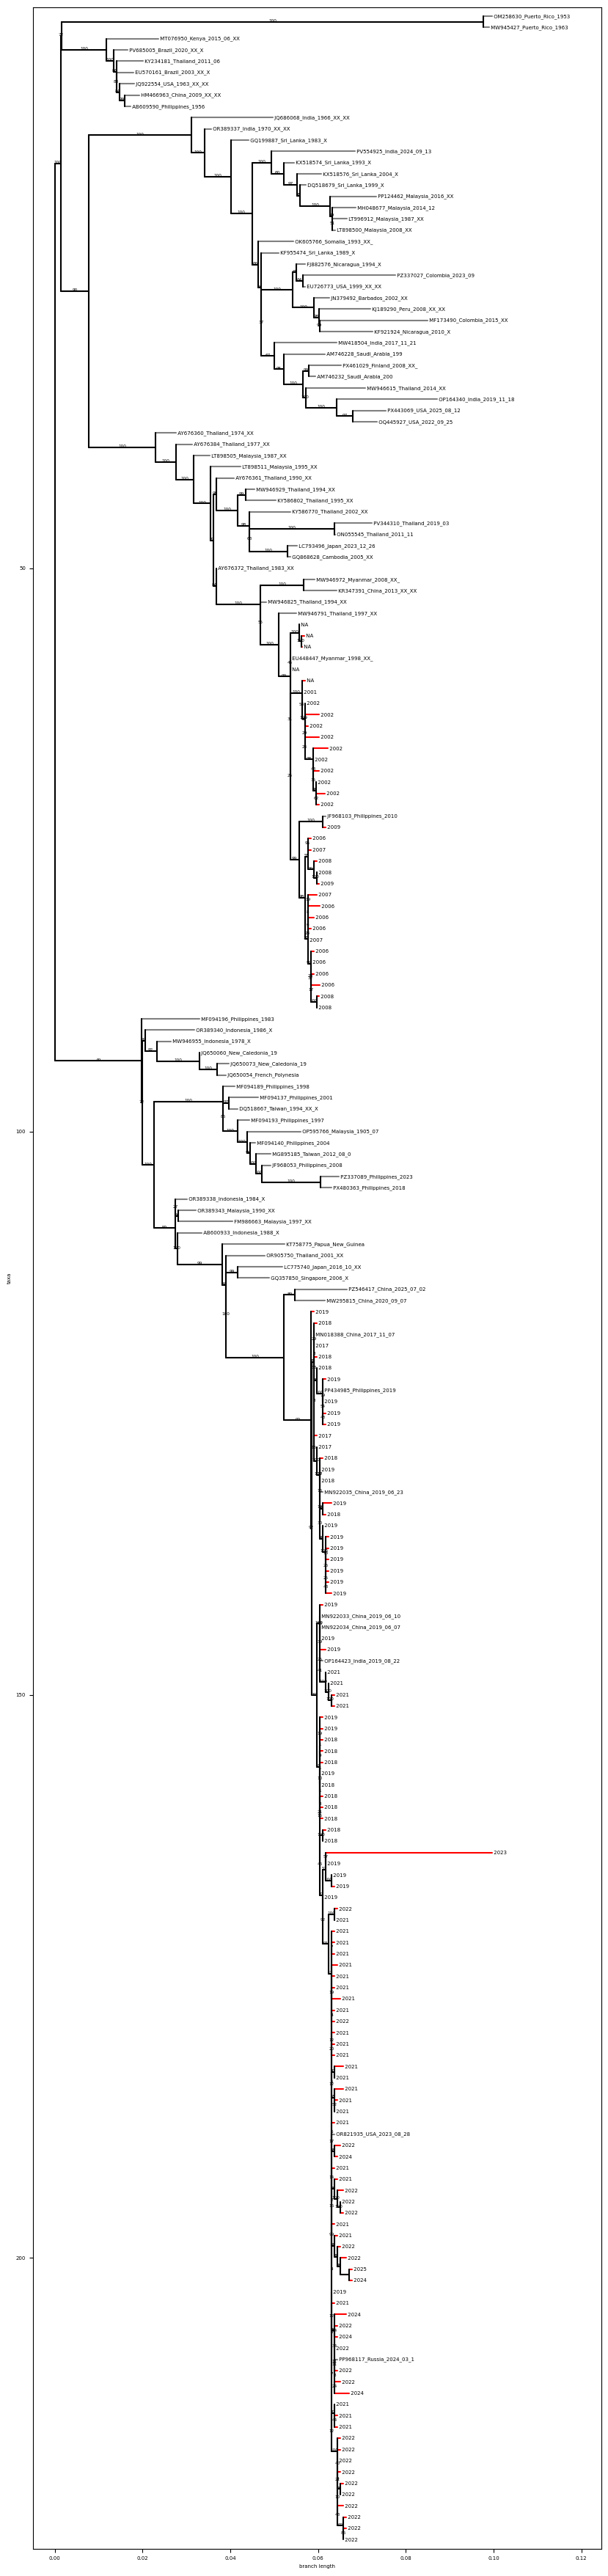

In [73]:
from Bio import Phylo
import matplotlib.pyplot as plt

tree = Phylo.read("/content/denv3_E.contree", "newick")
tree.root_at_midpoint()
tree.ladderize()

for t in tree.get_terminals():
    t.color = "red" if t.name.startswith("BD_") else "gray"

def label(c):
    if not c.is_terminal():
        return ""
    if c.name.startswith("BD_"):
        return c.name.split("_")[-1]
    return c.name[:25]

plt.rc("font", size=5)
fig = plt.figure(figsize=(10, 45))
ax = fig.add_subplot(1, 1, 1)
Phylo.draw(tree, label_func=label, do_show=False, axes=ax)
fig.savefig("/content/tree_denv3_E.png", dpi=150, bbox_inches="tight")
plt.show()

In [74]:
def year_of_tip(name):
    last = name.split("_")[-1]
    return int(last) if last.isdigit() else None

clusters = []
def walk(clade):
    tips = clade.get_terminals()
    if all(t.name.startswith("BD_") for t in tips):
        clusters.append(clade)
        return
    for c in clade.clades:
        walk(c)

walk(tree.root)

rows = []
for c in clusters:
    tips = c.get_terminals()
    yrs = [year_of_tip(t.name) for t in tips if year_of_tip(t.name)]
    first = min(yrs) if yrs else None
    last = max(yrs) if yrs else None
    rows.append([len(tips), first, last, len(tips) - len(yrs)])

cl = pd.DataFrame(rows, columns=["n_tips", "first_year", "last_year", "no_year"])
cl = cl.sort_values("n_tips", ascending=False)

print(len(cl))
print((cl["n_tips"] == 1).sum(), "single-tip groups")
print(cl.head(25).to_string())

47
26 single-tip groups
    n_tips  first_year  last_year  no_year
4       16      2006.0     2009.0        0
46      13      2021.0     2022.0        0
2       12      2001.0     2002.0        1
38      11      2021.0     2025.0        0
17       9      2018.0     2019.0        0
23       9      2018.0     2019.0        0
35       5      2021.0     2021.0        0
25       4      2019.0     2023.0        0
21       4      2021.0     2021.0        0
34       3      2021.0     2021.0        0
0        3         NaN        NaN        3
12       2      2019.0     2019.0        0
33       2      2021.0     2022.0        0
42       2      2022.0     2024.0        0
32       2      2021.0     2021.0        0
45       2      2022.0     2024.0        0
24       2      2018.0     2018.0        0
16       2      2018.0     2019.0        0
37       2      2022.0     2024.0        0
27       2      2021.0     2022.0        0
29       2      2021.0     2021.0        0
11       1      2019.0     201

In [75]:
tips_all = tree.get_terminals()
bd_new = [t for t in tips_all if t.name.startswith("BD_") and (year_of_tip(t.name) or 0) >= 2017]
bd_old = [t for t in tips_all if t.name.startswith("BD_") and (year_of_tip(t.name) or 9999) <= 2009]

for name, group in [("2017+", bd_new), ("<=2009", bd_old)]:
    mrca = tree.common_ancestor(group)
    tips = mrca.get_terminals()
    foreign = [t.name for t in tips if not t.name.startswith("BD_")]
    print(name, len(group), "BD tips; common clade has", len(tips), "tips,", len(foreign), "foreign; support:", mrca.confidence)
    print(foreign[:15])

2017+ 102 BD tips; common clade has 110 tips, 8 foreign; support: 92
['MN018388_China_2017_11_07', 'PP434985_Philippines_2019_06_XX', 'MN922035_China_2019_06_23', 'MN922033_China_2019_06_10', 'MN922034_China_2019_06_07', 'OP164423_India_2019_08_22', 'OR821935_USA_2023_08_28', 'PP968117_Russia_2024_03_13']
<=2009 28 BD tips; common clade has 30 tips, 1 foreign; support: 25
['JF968103_Philippines_2010_XX_XX']


In [76]:
g3 = meta_all[(meta_all["genotype"] == "3I") & (meta_all["country"] != "Bangladesh")]
g3 = g3[g3["accession"].isin(glob_E)].copy()
g3["year"] = pd.to_numeric(g3["date"].astype(str).str[:4], errors="coerce")
g3 = g3[g3["year"].notna()]
g3["bin"] = (g3["year"] // 5) * 5

print(len(g3))
print(g3["minor_lineage"].value_counts().head(12))
print(g3["country"].value_counts().head(8))

1457
minor_lineage
3I_A        516
3I_C.2.1    133
3I_A.1      128
3I_A.1.2    124
3I_C.2      120
3I_C         90
3I_C.1       66
3I_A.1.1     64
3I_B         61
3I_C.2.3     60
3I_C.2.2     51
3I_A.2       25
Name: count, dtype: int64
country
Philippines    447
Indonesia      337
Taiwan         100
China           78
Singapore       66
Malaysia        66
Sri Lanka       61
Myanmar         35
Name: count, dtype: int64


In [77]:
near_lin = g3[g3["minor_lineage"].astype(str).str.startswith("3I_A")]
other = g3[~g3.index.isin(near_lin.index)].sample(frac=1, random_state=1)
other = other.drop_duplicates(subset=["minor_lineage", "country", "bin"]).head(150)

add_ids = set(near_lin["accession"]) | set(other["accession"])

have = set()
for rec in SeqIO.parse("/content/tree_denv3.fa", "fasta"):
    if not rec.id.startswith("BD_"):
        have.add(rec.id.split("_")[0])

add_ids = [a for a in add_ids if a not in have]
print(len(near_lin), len(other), len(add_ids))

old = open("/content/tree_denv3.fa").read()
with open("/content/tree_denv3_v2.fa", "w") as f:
    f.write(old)
    for a in sorted(add_ids):
        name = clean(f"{a}_{country.get(a)}_{date.get(a)}")
        f.write(f">{name}\n{glob_E[a][1]}\n")

print(len(list(SeqIO.parse("/content/tree_denv3_v2.fa", "fasta"))))

857 68 903
1128


In [78]:
!iqtree2 --version | head -3

IQ-TREE multicore version 2.0.7 for Linux 64-bit built Apr  1 2024
Developed by Bui Quang Minh, Nguyen Lam Tung, Olga Chernomor,
Heiko Schmidt, Dominik Schrempf, Michael Woodhams.


In [79]:
gen = df[(df["Length"] > 9000) & (~df["suspect_template"]) & (~df["suspect_ref"]) & (df["serotype"] != "DENV-4")].copy()
gen = gen[~gen["Isolate"].astype(str).str.contains("mutant")]
gen = gen[gen["n_frac"] <= 0.10]

print(len(gen))
print(pd.crosstab(gen["year"], gen["serotype"]))

69
serotype  DENV-1  DENV-2  DENV-3
year                            
2002.0         0       0       4
2017.0         2       7       2
2019.0         0       1      12
2020.0         0       0       1
2021.0         0       0      21
2023.0         0       0       1
2024.0         0       1       0
2025.0         4      12       1


In [80]:
pool = []
for acc, seq in glob["denv3"].items():
    if len(seq) < 10000 or country.get(acc) == "Bangladesh" or pd.isna(year_of(acc)):
        continue
    non_acgt = len(seq) - sum(seq.count(b) for b in "ACGT")
    if non_acgt / len(seq) <= 0.01:
        pool.append(acc)
print(len(pool))

pi = ginfo.reindex(pool).reset_index()
pi["year"] = pd.to_numeric(pi["date"].astype(str).str[:4], errors="coerce")
pi["bin"] = (pi["year"] // 5) * 5

fam = pi[pi["minor_lineage"].astype(str).str.startswith("3I_A")]
fam = fam.sample(frac=1, random_state=1).drop_duplicates(subset=["minor_lineage", "country", "year"]).head(150)

rest = pi[~pi["accession"].isin(fam["accession"])]
rest = rest.sample(frac=1, random_state=1).drop_duplicates(subset=["major_lineage", "bin"])

keep = list(fam["accession"]) + list(rest["accession"])
mine = gen[gen["serotype"] == "DENV-3"]

with open("/content/tree_g3.fa", "w") as f:
    for _, r in mine.iterrows():
        f.write(f">BD_{r['Accession']}_{int(r['year']) if pd.notna(r['year']) else 'NA'}\n{seqs[r['Accession']]}\n")
    for a in keep:
        name = clean(f"{a}_{country.get(a)}_{date.get(a)}")
        f.write(f">{name}\n{glob['denv3'][a]}\n")

print("Bangladesh:", len(mine), "world:", len(keep))

3150
Bangladesh: 42 world: 130


In [81]:
!mafft --auto --thread 2 /content/tree_g3.fa > /content/aln_g3.fa 2> /content/mafft_g3.log
aln = list(SeqIO.parse("/content/aln_g3.fa", "fasta"))
print(len(aln), len(aln[0].seq))

172 10715


In [82]:
!apt-get -qq install -y fasttree > /dev/null
!which fasttree FastTree

/usr/bin/fasttree
/usr/bin/FastTree


In [83]:
!fasttree -nt -gtr -gamma /content/aln_g3.fa > /content/g3.tree 2> /content/fasttree_g3.log
!tail -3 /content/fasttree_g3.log

     87.91 seconds: Optimizing alpha round 1
Gamma(20) LogLk = -82459.067 alpha = 0.315 rescaling lengths by 1.039
Total time: 88.04 seconds Unique: 169/172 Bad splits: 0/166


In [84]:
tree = Phylo.read("/content/g3.tree", "newick")
tree.root_at_midpoint()
tips = tree.get_terminals()
bd = [t for t in tips if t.name.startswith("BD_")]
print(len(tips), len(bd))

172 42


In [85]:
rows = []
for t in bd:
    best = None
    for o in tips:
        if o.name.startswith("BD_"):
            continue
        d = tree.distance(t, o)
        if best is None or d < best[1]:
            best = (o.name, d)
    rows.append([t.name, best[0], round(best[1] * 10716)])

near_g = pd.DataFrame(rows, columns=["bd", "nearest_foreign", "approx_subs"])
print(near_g.sort_values("approx_subs").to_string())

                  bd               nearest_foreign  approx_subs
25  BD_ON908231_2019     MN922033_China_2019_06_10            1
27  BD_ON908235_2019     MN922033_China_2019_06_10            3
28  BD_ON907583_2019     MN922033_China_2019_06_10            3
31  BD_LC436676_2017     MN018388_China_2017_11_07           13
30  BD_LC436677_2017     MN922033_China_2019_06_10           16
24  BD_MW396468_2019     MN922033_China_2019_06_10           18
29  BD_MW396464_2019     MN922033_China_2019_06_10           19
26  BD_ON116130_2021     MN922033_China_2019_06_10           20
23  BD_PP711274_2019     MN922033_China_2019_06_10           21
32  BD_MW396469_2019     MN018388_China_2017_11_07           25
15  BD_ON115812_2021    PP968117_Russia_2024_03_13           27
9   BD_OP740753_2021    PP968117_Russia_2024_03_13           28
10  BD_OK079104_2020    PP968117_Russia_2024_03_13           28
11  BD_OP741243_2021    PP968117_Russia_2024_03_13           28
12  BD_ON127553_2021    PP968117_Russia_

In [86]:
new = [t for t in bd if (year_of_tip(t.name) or 0) >= 2017]
m = tree.common_ancestor(new)
ts = m.get_terminals()
print(len(new), "BD genomes;", len(ts), "tips in clade; support:", m.confidence)

for t in ts:
    if not t.name.startswith("BD_"):
        print(t.name)

38 BD genomes; 41 tips in clade; support: 0.988
PP968117_Russia_2024_03_13
MN922033_China_2019_06_10
MN018388_China_2017_11_07


In [87]:
old = [t for t in bd if (year_of_tip(t.name) or 9999) <= 2009]
m2 = tree.common_ancestor(old)
print(len(old), "old BD genomes;", len(m2.get_terminals()), "tips in clade; support:", m2.confidence)
print([t.name for t in m2.get_terminals() if not t.name.startswith("BD_")])

4 old BD genomes; 4 tips in clade; support: 1.0
[]


In [88]:
new = [t for t in bd if (year_of_tip(t.name) or 0) >= 2017]
m = tree.common_ancestor(new)

def parent_of(tree, clade):
    for c in tree.find_clades():
        if clade in c.clades:
            return c

parent = parent_of(tree, m)
for s in parent.clades:
    if s is m:
        continue
    ts = s.get_terminals()
    print(len(ts), "tips; support:", s.confidence)
    for t in ts[:25]:
        print(t.name)

1 tips; support: None
MN018377_China_2015_12_22


In [89]:
import numpy as np

rows = []
for t in m.get_terminals():
    y = year_of_tip(t.name)
    if t.name.startswith("BD_") and y:
        rows.append([t.name, y, tree.distance(m, t)])

rt = pd.DataFrame(rows, columns=["tip", "year", "dist"])

def fit(d):
    slope, b = np.polyfit(d["year"], d["dist"], 1)
    r = np.corrcoef(d["year"], d["dist"])[0, 1]
    return round(slope, 6), round(r ** 2, 3)

print(len(rt), fit(rt))
print(fit(rt[rt["tip"] != "BD_PQ815901_2023"]))

38 (np.float64(0.001441), np.float64(0.497))
(np.float64(0.000991), np.float64(0.889))


In [90]:
rt2 = rt[rt["tip"] != "BD_PQ815901_2023"].copy()
slope, b = np.polyfit(rt2["year"], rt2["dist"], 1)
print("rate:", round(slope, 6), "approx root year:", round(-b / slope, 1))

rng = np.random.default_rng(1)

boots = []
for _ in range(1000):
    s = rt2.sample(len(rt2), replace=True, random_state=int(rng.integers(1e9)))
    if s["year"].nunique() < 3:
        continue
    sl, bb = np.polyfit(s["year"], s["dist"], 1)
    if sl > 0:
        boots.append((sl, -bb / sl))
boots = np.array(boots)
print("rate 95% range:", np.percentile(boots[:, 0], [2.5, 50, 97.5]).round(6))
print("root year 95% range:", np.percentile(boots[:, 1], [2.5, 50, 97.5]).round(1))

obs = np.corrcoef(rt2["year"], rt2["dist"])[0, 1] ** 2
perm = []
for _ in range(1000):
    y = rng.permutation(rt2["year"].values)
    perm.append(np.corrcoef(y, rt2["dist"])[0, 1] ** 2)
print("R2:", round(obs, 3), " fraction of shuffles >= observed:", np.mean(np.array(perm) >= obs))

rate: 0.000991 approx root year: 2016.9
rate 95% range: [0.000838 0.000985 0.001107]
root year 95% range: [2016.2 2016.8 2017.3]
R2: 0.889  fraction of shuffles >= observed: 0.0


In [91]:
have = set(r.id.split("_")[0] for r in SeqIO.parse("/content/tree_g3.fa", "fasta") if not r.id.startswith("BD_"))
add = [a for a in pi[pi["minor_lineage"] == "3I_A.2"]["accession"] if a not in have]

print(len(add), "to add")
print(pi[pi["accession"].isin(add)][["accession", "country", "date", "strain"]].to_string())

with open("/content/tree_g3_v2.fa", "w") as f:
    f.write(open("/content/tree_g3.fa").read())
    for a in add:
        name = clean(f"{a}_{country.get(a)}_{date.get(a)}")
        f.write(f">{name}\n{glob['denv3'][a]}\n")

print(len(list(SeqIO.parse("/content/tree_g3_v2.fa", "fasta"))))

2 to add
     accession country        date     strain
1969  MN922034   China  2019-06-07  19XN14065
1970  MN922035   China  2019-06-23  19XN15780
174


In [92]:
!mafft --auto --thread 2 /content/tree_g3_v2.fa > /content/aln_g3_v2.fa 2> /content/mafft_g3_v2.log
!fasttree -nt -gtr -gamma /content/aln_g3_v2.fa > /content/g3_v2.tree 2> /content/fasttree_g3_v2.log
!tail -2 /content/fasttree_g3_v2.log

Gamma(20) LogLk = -82559.208 alpha = 0.315 rescaling lengths by 1.039
Total time: 87.81 seconds Unique: 171/174 Bad splits: 0/168


In [93]:
tree = Phylo.read("/content/g3_v2.tree", "newick")
tree.root_at_midpoint()
tips = tree.get_terminals()
bd = [t for t in tips if t.name.startswith("BD_")]
new = [t for t in bd if (year_of_tip(t.name) or 0) >= 2017]
m = tree.common_ancestor(new)

print(len(tips), len(bd), len(m.get_terminals()), m.confidence)
print([t.name for t in m.get_terminals() if not t.name.startswith("BD_")])

parent = parent_of(tree, m)
for s in parent.clades:
    if s is not m:
        print([t.name for t in s.get_terminals()][:20], s.confidence)

174 42 43 0.988
['PP968117_Russia_2024_03_13', 'MN922034_China_2019_06_07', 'MN922033_China_2019_06_10', 'MN922035_China_2019_06_23', 'MN018388_China_2017_11_07']
['MN018377_China_2015_12_22'] None


In [94]:
stem = m.branch_length
rate = 0.000991
print("stem length:", round(stem, 6))
print("approx years:", round(stem / rate, 1))
print("approx split year:", round(2016.9 - stem / rate, 1))

stem length: 0.001632
approx years: 1.6
approx split year: 2015.3


In [95]:
def fix_date(s):
    s = str(s)
    parts = s.split("-")
    if len(parts) == 1:
        return parts[0] + "-XX-XX"
    if len(parts) == 2:
        return s + "-XX"
    return s

dd = df.set_index("Accession")
dates = []

for rec in SeqIO.parse("/content/aln_g3_v2.fa", "fasta"):
    name = rec.id
    if name.startswith("BD_"):
        acc = name.split("_")[1]
        cd = dd.loc[acc, "Collection_Date"]
        if pd.notna(cd):
            d = fix_date(cd)
        else:
            d = str(int(dd.loc[acc, "year"])) + "-XX-XX"
    else:
        acc = name.split("_")[0]
        d = fix_date(date.get(acc))
    dates.append([name, d])

pd.DataFrame(dates, columns=["name", "date"]).to_csv("/content/dates_g3.csv", index=False)
print(len(dates))
print(dates[:3])
print(dates[-3:])

174
[['BD_OZ484500_2025', '2025-11-12'], ['BD_PQ815901_2023', '2023-09-29'], ['BD_PP711274_2019', '2019-08-13']]
[['MW946955_Indonesia_1978_XX_XX', '1978-XX-XX'], ['MN922034_China_2019_06_07', '2019-06-07'], ['MN922035_China_2019_06_23', '2019-06-23']]


In [96]:
!pip install phylo-treetime -q

!treetime --tree /content/g3_v2.tree --aln /content/aln_g3_v2.fa --dates /content/dates_g3.csv --name-column name --date-column date --clock-filter 3 --confidence --outdir /content/tt_g3 > /content/treetime_g3.log 2>&1

!tail -30 /content/treetime_g3.log



--- molecular clock model (saved as /content/tt_g3/molecular_clock.txt):

Root-Tip-Regression:
 --rate:	6.927e-04
 --r^2:  	0.95

--- saved tree as 
	 /content/tt_g3/timetree.pdf

--- root-to-tip plot saved to  
	/content/tt_g3/root_to_tip_regression.pdf

--- alignment including ancestral nodes saved as  
	 /content/tt_g3/ancestral_sequences.fasta

--- saved divergence times in 
	 /content/tt_g3/dates.tsv

--- tree saved in nexus format as  
	 /content/tt_g3/timetree.nexus

--- tree saved in auspice json format as  
	 /content/tt_g3/auspice_tree.json

--- divergence tree saved in nexus format as  
	 /content/tt_g3/divergence_tree.nexus

--- saved detected outliers as /content/tt_g3/outliers.tsv


In [97]:
!ls /content/tt_g3
print(open("/content/tt_g3/molecular_clock.txt").read())

dt = pd.read_csv("/content/tt_g3/dates.tsv", sep="\t")
print(dt.columns.tolist())
print(dt.head(5).to_string())
print(dt[dt.iloc[:, 0].astype(str).str.startswith("NODE")].head(5).to_string())

!grep -i -E "ignor|outlier|excluded" /content/treetime_g3.log | head

ancestral_sequences.fasta  outliers.tsv
auspice_tree.json	   root_to_tip_regression.pdf
branch_mutations.txt	   sequence_evolution_model.txt
dates.tsv		   timetree.nexus
divergence_tree.nexus	   timetree.pdf
molecular_clock.txt	   trace_run.log
Root-Tip-Regression:
 --rate:	6.927e-04
 --r^2:  	0.95


['#node', 'date', 'numeric date']
                             #node        date numeric date
0                     NODE_0000001  1893-05-13  1893.362151
1                     NODE_0000121  1953-10-16  1953.790574
2  OM258630_Puerto_Rico_1953_XX_XX  1953-12-31  1953.998630
3  MW945427_Puerto_Rico_1963_XX_XX  1963-01-01  1963.001370
4                     NODE_0000120  1937-11-17  1937.878547
          #node        date numeric date
0  NODE_0000001  1893-05-13  1893.362151
1  NODE_0000121  1953-10-16  1953.790574
4  NODE_0000120  1937-11-17  1937.878547
5  NODE_0000122  1937-11-17  1937.878547
6  NODE_0000123  1955-12-25  1955.983193
6.17	TreeTime.reroot: rerooting will ignore covariance and

In [98]:
!treetime --tree /content/g3_v2.tree --aln /content/aln_g3_v2.fa --dates /content/dates_g3.csv --name-column name --date-column date --clock-filter 3 --covariation --confidence --outdir /content/tt_g3b > /content/treetime_g3b.log 2>&1
!tail -12 /content/treetime_g3b.log

	 /content/tt_g3b/dates.tsv

--- tree saved in nexus format as  
	 /content/tt_g3b/timetree.nexus

--- tree saved in auspice json format as  
	 /content/tt_g3b/auspice_tree.json

--- divergence tree saved in nexus format as  
	 /content/tt_g3b/divergence_tree.nexus

--- saved detected outliers as /content/tt_g3b/outliers.tsv


In [99]:
print(open("/content/tt_g3b/molecular_clock.txt").read())
print(open("/content/tt_g3b/outliers.tsv").read()[:3000])

Root-Tip-Regression:
 --rate:	3.871e-04 +/- 1.07e-05 (one std-dev)
 --chi^2:	375469.01
 --r^2:  	0.68


	given_date	apparent_date	residual
PV554924_India_2024_09_13	2024.700819672131	2348.59524568514	3.2860491545418493
MG721059_India_2016_XX_XX	2016.5	2366.089420947481	3.546736000622326
LT996912_Malaysia_1987_XX_XX	1987.5	2318.281181215531	3.355918267108405
LT996910_Malaysia_2010_XX_XX	2010.5	2318.281181215531	3.1225733112077845
ON055565_Thailand_2010_02_16	2010.127397260274	2315.3771177684957	3.0968905465507808
OM865811_Bhutan_2019_08_31	2019.664383561644	2376.2143233899883	3.6173534776353944
PX395899_USA_2024_12_31	2024.9986338797814	2429.6006758618914	4.104862854070285
PV763904_Brazil_2025_02_03	2025.0917808219178	2424.138110893874	4.048497751867179
PP983029_Colombia_2024_02_09	2024.1079234972678	2415.859227051937	3.9744865500858713
MH450296_Venezuela_2015_09_23	2015.727397260274	2354.4088906603297	3.436070353990971
PZ337091_Philippines_2024_01_16	2024.042349726776	2398.585737941406

In [100]:
import json

js = json.load(open("/content/tt_g3b/auspice_tree.json"))
root = js["tree"]

def tips_of(node):
    if "children" not in node:
        return [node["name"]]
    out = []
    for c in node["children"]:
        out += tips_of(c)
    return out

def path_to_mrca(node, targets, path=None):
    path = (path or []) + [node]
    for c in node.get("children", []):
        if targets <= set(tips_of(c)):
            return path_to_mrca(c, targets, path)
    return path

def info(node):
    d = node["node_attrs"]["num_date"]
    return round(d["value"], 1), [round(x, 1) for x in d.get("confidence", [])]

out_names = set()
for line in open("/content/tt_g3b/outliers.tsv"):
    if line.startswith("#") or not line.strip():
        continue
    out_names.add(line.split("\t")[0].strip())
print("outliers:", out_names)

all_tips = tips_of(root)
bd_new = set(t for t in all_tips if t.startswith("BD_") and t.split("_")[-1].isdigit() and int(t.split("_")[-1]) >= 2017)
bd_old = set(t for t in all_tips if t.startswith("BD_") and t.split("_")[-1].isdigit() and int(t.split("_")[-1]) <= 2009)

def report(label, targets):
    p = path_to_mrca(root, targets)
    print(label, "| tips in clade:", len(tips_of(p[-1])), "| MRCA:", info(p[-1]), "| parent:", info(p[-2]) if len(p) > 1 else None)

report("BD 2017+ all", bd_new)
report("BD 2017+ without outliers", bd_new - out_names)
report("BD 2002 genomes", bd_old)

p = path_to_mrca(root, bd_new - out_names)
for c in p[-2]["children"]:
    print(len(tips_of(c)), tips_of(c)[:4])

outliers: {'', 'BD_ON115815_2021', 'MW788909_Myanmar_2018_08_XX', 'BD_MW396469_2019', 'OP595764_Malaysia_2019_05_01', 'OQ103317_Sri_Lanka_2022_05_20', 'BD_ON127538_2021', 'PZ546417_China_2025_07_02', 'PP968117_Russia_2024_03_13', 'BD_ON908235_2019', 'BD_MW396468_2019', 'MT921575_Australia_2016_XX_XX', 'BD_ON115817_2021', 'BD_ON907583_2019', 'OM865811_Bhutan_2019_08_31', 'PX395899_USA_2024_12_31', 'MW295815_China_2020_09_07', 'BD_ON103303_2021', 'PP766873_Sri_Lanka_2023_06_05', 'MN018377_China_2015_12_22', 'BD_MW396467_2019', 'PX395918_USA_2025_07_20', 'MN018387_China_2017_09_18', 'BD_ON111446_2021', 'PP152118_Indonesia_2019_XX_XX', 'PP983029_Colombia_2024_02_09', 'OR394032_Sri_Lanka_2019_11_29', 'BD_MW396465_2019', 'BD_PP711274_2019', 'BD_ON127551_2021', 'BD_ON127534_2021', 'BD_OK079104_2020', 'OP595765_Malaysia_2020_11_01', 'MN922033_China_2019_06_10', 'BD_ON115030_2021', 'MN922039_China_2019_07_30', 'BD_ON116130_2021', 'OQ103113_Sri_Lanka_2020_01_01', 'MN922035_China_2019_06_23', 'MN

In [101]:
import subprocess

def build_genome_set(sero, k, prefixes, outname, cap=150):
    pool = []
    for acc, seq in glob[k].items():
        if len(seq) < 10000 or country.get(acc) == "Bangladesh" or pd.isna(year_of(acc)):
            continue
        non_acgt = len(seq) - sum(seq.count(b) for b in "ACGT")
        if non_acgt / len(seq) <= 0.01:
            pool.append(acc)

    p2 = ginfo.reindex(pool).reset_index()
    p2["year"] = pd.to_numeric(p2["date"].astype(str).str[:4], errors="coerce")
    p2["bin"] = (p2["year"] // 5) * 5

    fam = p2[p2["minor_lineage"].astype(str).str.startswith(tuple(prefixes))]
    fam = fam.sample(frac=1, random_state=1).drop_duplicates(subset=["minor_lineage", "country", "year"]).head(cap)
    rest = p2[~p2["accession"].isin(fam["accession"])]
    rest = rest.sample(frac=1, random_state=1).drop_duplicates(subset=["major_lineage", "bin"])
    keep = list(fam["accession"]) + list(rest["accession"])

    mine = gen[gen["serotype"] == sero]
    with open(outname, "w") as f:
        for _, r in mine.iterrows():
            f.write(f">BD_{r['Accession']}_{int(r['year'])}\n{seqs[r['Accession']]}\n")
        for a in keep:
            f.write(f">{clean(f'{a}_{country.get(a)}_{date.get(a)}')}\n{glob[k][a]}\n")
    print(sero, "pool:", len(pool), "Bangladesh:", len(mine), "world:", len(keep))

def align_and_tree(fa, tag):
    subprocess.run(f"mafft --auto --thread 2 {fa} > /content/aln_{tag}.fa 2> /content/mafft_{tag}.log", shell=True)
    subprocess.run(f"fasttree -nt -gtr -gamma /content/aln_{tag}.fa > /content/{tag}.tree 2> /content/fasttree_{tag}.log", shell=True)
    print(open(f"/content/fasttree_{tag}.log").read().strip().split("\n")[-1])

def summarize(treefile, alnfile):
    t = Phylo.read(treefile, "newick")
    t.root_at_midpoint()
    L = len(next(SeqIO.parse(alnfile, "fasta")).seq)
    tp = t.get_terminals()
    b = [x for x in tp if x.name.startswith("BD_")]
    print(len(tp), "tips,", len(b), "Bangladesh")

    groups = []
    def walk(c):
        ts = c.get_terminals()
        if all(x.name.startswith("BD_") for x in ts):
            groups.append(ts)
            return
        for ch in c.clades:
            walk(ch)
    walk(t.root)

    rows = []
    for g in groups:
        yrs = [year_of_tip(x.name) for x in g if year_of_tip(x.name)]
        rows.append([len(g), min(yrs) if yrs else None, max(yrs) if yrs else None])
    gdf = pd.DataFrame(rows, columns=["n", "first", "last"]).sort_values("n", ascending=False)
    print(len(gdf), "Bangladesh-only groups,", (gdf["n"] == 1).sum(), "single")
    print(gdf.head(12).to_string())

    out = []
    for x in b:
        best = None
        for o in tp:
            if o.name.startswith("BD_"):
                continue
            d = t.distance(x, o)
            if best is None or d < best[1]:
                best = (o.name, d)
        out.append([x.name, best[0], round(best[1] * L)])
    nd = pd.DataFrame(out, columns=["bd", "nearest_foreign", "approx_subs"]).sort_values("approx_subs")
    print(nd["approx_subs"].describe())
    print(nd.head(8).to_string())
    print(nd.tail(6).to_string())
    return t

In [102]:
build_genome_set("DENV-2", "denv2", ["2II_F", "2II_A.2"], "/content/tree_g2.fa")
align_and_tree("/content/tree_g2.fa", "g2")
t_g2 = summarize("/content/g2.tree", "/content/aln_g2.fa")

DENV-2 pool: 7727 Bangladesh: 21 world: 287
Total time: 185.85 seconds Unique: 307/308 Bad splits: 0/304
308 tips, 21 Bangladesh
5 Bangladesh-only groups, 1 single
    n  first  last
3  13   2024  2025
0   3   2017  2017
1   2   2017  2019
4   2   2017  2017
2   1   2017  2017
count    21.000000
mean     70.238095
std      13.805451
min      34.000000
25%      70.000000
50%      74.000000
75%      77.000000
max      85.000000
Name: approx_subs, dtype: float64
                  bd            nearest_foreign  approx_subs
19  BD_LC436671_2017  MH822952_India_2014_09_16           34
20  BD_LC436670_2017  MH822952_India_2014_09_16           36
15  BD_PX701199_2024    PQ154996_USA_2023_10_03           54
9   BD_OZ484498_2025    PQ154996_USA_2023_10_03           62
4   BD_LC436672_2017   OM791800_Peru_2019_09_26           64
8   BD_OZ484495_2025    PQ154996_USA_2023_10_03           70
13  BD_OZ484509_2025    PQ154996_USA_2023_10_03           72
6   BD_OZ484518_2025    PQ154996_USA_2023_10_03 

In [103]:
for k, tag in [("denv1", "e1"), ("denv2", "e2")]:
    align_and_tree(f"/content/tree_{k}.fa", tag)

t_e1 = summarize("/content/e1.tree", "/content/aln_e1.fa")
t_e2 = summarize("/content/e2.tree", "/content/aln_e2.fa")

Total time: 16.19 seconds Unique: 213/320 Bad splits: 0/210
Total time: 19.55 seconds Unique: 269/282 Bad splits: 0/266
320 tips, 17 Bangladesh
9 Bangladesh-only groups, 4 single
   n  first  last
4  3   2017  2018
8  3   2025  2025
6  3   2017  2018
0  2   2017  2019
3  2   2018  2019
1  1   2018  2018
2  1   2019  2019
5  1   2017  2017
7  1   2009  2009
count    17.000000
mean      4.882353
std       5.808209
min       1.000000
25%       2.000000
50%       2.000000
75%       4.000000
max      17.000000
Name: approx_subs, dtype: float64
                  bd                nearest_foreign  approx_subs
2   BD_OQ826842_2018     MG894942_Taiwan_2016_08_26            1
13  BD_JN036371_2009      HQ149733_China_2009_XX_XX            1
11  BD_OQ826841_2018  MF033243_Singapore_2016_01_XX            1
9   BD_LC436608_2017   PP124174_Malaysia_2017_XX_XX            1
8   BD_OQ826844_2018     MG894942_Taiwan_2016_08_26            2
0   BD_LC436667_2017   PP124174_Malaysia_2017_XX_XX            2


In [104]:
!zip -q /content/results_day1.zip /content/*.tree /content/dates_g3.csv /content/dengue_step6_flags.csv /content/tt_g3b/dates.tsv /content/tt_g3b/molecular_clock.txt /content/tt_g3b/outliers.tsv

from google.colab import files
files.download("/content/results_day1.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [105]:
dm = pd.read_csv("/content/dates_g3.csv")
dm = dict(zip(dm["name"], dm["date"]))

lin_bd = dict(zip(df["Accession"], df["ns_minor"]))
lin_w = dict(zip(meta_all["accession"], meta_all["minor_lineage"]))

keep, dropped = [], []
for rec in SeqIO.parse("/content/aln_g3_v2.fa", "fasta"):
    n = rec.id
    if n.startswith("BD_"):
        lin = lin_bd.get(n.split("_")[1])
    else:
        lin = lin_w.get(n.split("_")[0])
    yr = int(dm[n][:4])
    if str(lin).startswith("3I_A") and 1995 <= yr <= 2026:
        keep.append(n)
    else:
        dropped.append((n, lin, yr))

print(len(keep), "kept;", len(dropped), "dropped")
print([d for d in dropped if str(d[1]).startswith("3I_A")])
print(sum(1 for n in keep if n.startswith("BD_")), "Bangladesh in kept")

105 kept; 69 dropped
[('PX297389_Malaysia_1990_XX_XX', '3I_A', 1990), ('OR389338_Indonesia_1984_XX_XX', '3I_A', 1984), ('OR389339_Indonesia_1985_XX_XX', '3I_A', 1985), ('OK605763_Indonesia_1985_XX_XX', '3I_A', 1985), ('OR389343_Malaysia_1990_XX_XX', '3I_A', 1990)]
38 Bangladesh in kept


In [106]:
def write_subset(names, tag):
    names = set(names)
    recs = [r for r in SeqIO.parse("/content/aln_g3_v2.fa", "fasta") if r.id in names]
    SeqIO.write(recs, f"/content/aln_{tag}.fa", "fasta")
    pd.DataFrame([[n, dm[n]] for n in names], columns=["name", "date"]).to_csv(f"/content/dates_{tag}.csv", index=False)
    subprocess.run(f"fasttree -nt -gtr -gamma /content/aln_{tag}.fa > /content/{tag}.tree 2> /content/fasttree_{tag}.log", shell=True)
    return len(recs)

def run_tt(tag):
    cmd = (f"treetime --tree /content/{tag}.tree --aln /content/aln_{tag}.fa --dates /content/dates_{tag}.csv "
           f"--name-column name --date-column date --clock-filter 3 --covariation --confidence "
           f"--outdir /content/tt_{tag} > /content/treetime_{tag}.log 2>&1")
    subprocess.run(cmd, shell=True)

def bd_clade_dates(tag):
    js = json.load(open(f"/content/tt_{tag}/auspice_tree.json"))
    rt = js["tree"]
    tips = tips_of(rt)

    out_names = set()
    for line in open(f"/content/tt_{tag}/outliers.tsv"):
        if line.startswith("#") or not line.strip():
            continue
        out_names.add(line.split("\t")[0].strip())

    bd = set(t for t in tips if t.startswith("BD_"))
    print(tag, "| tips:", len(tips), "| BD:", len(bd), "| outliers:", len(out_names), "| BD outliers:", len(out_names & bd))
    print(open(f"/content/tt_{tag}/molecular_clock.txt").read().strip())

    p = path_to_mrca(rt, bd - out_names)
    print("MRCA of BD genomes:", info(p[-1]), "| tips in clade:", len(tips_of(p[-1])))
    if len(p) > 1:
        print("parent node:", info(p[-2]))
    print()

In [107]:
foreign_in_clade = {"PP968117_Russia_2024_03_13", "MN922033_China_2019_06_10", "MN922034_China_2019_06_07",
                    "MN922035_China_2019_06_23", "MN018388_China_2017_11_07"}
long_branch = {"BD_PQ815901_2023", "BD_OZ484500_2025"}

runs = {
    "g3s": set(keep),
    "g3s_nof": set(keep) - foreign_in_clade,
    "g3s_nolong": set(keep) - long_branch,
}

for tag, names in runs.items():
    print(tag, write_subset(names, tag))
    run_tt(tag)

for tag in runs:
    bd_clade_dates(tag)

g3s 105
g3s_nof 100
g3s_nolong 103
g3s | tips: 105 | BD: 38 | outliers: 6 | BD outliers: 1
Root-Tip-Regression:
 --rate:	6.493e-04 +/- 2.75e-05 (one std-dev)
 --chi^2:	9739.68
 --r^2:  	0.91
MRCA of BD genomes: (2016.4, [2016.0, 2016.9]) | tips in clade: 43
parent node: (2013.9, [2012.9, 2014.9])

g3s_nof | tips: 100 | BD: 38 | outliers: 7 | BD outliers: 1
Root-Tip-Regression:
 --rate:	6.431e-04 +/- 2.81e-05 (one std-dev)
 --chi^2:	9845.06
 --r^2:  	0.90
MRCA of BD genomes: (2016.6, [2016.1, 2017.0]) | tips in clade: 38
parent node: (2014.0, [2013.0, 2015.0])

g3s_nolong | tips: 103 | BD: 36 | outliers: 6 | BD outliers: 0
Root-Tip-Regression:
 --rate:	6.310e-04 +/- 2.82e-05 (one std-dev)
 --chi^2:	9476.21
 --r^2:  	0.90
MRCA of BD genomes: (2016.4, [2015.9, 2016.8]) | tips in clade: 41
parent node: (2013.8, [2012.8, 2014.8])



In [108]:
!zip -q -r /content/results_day2.zip /content/tt_g3s /content/tt_g3s_nof /content/tt_g3s_nolong /content/g3s.tree /content/g3s_nof.tree /content/g3s_nolong.tree /content/dates_g3s.csv
from google.colab import files
files.download("/content/results_day2.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [109]:
def acc_of(name):
    parts = name.split("_")
    if parts[0] in ("NC", "NG", "NR") and len(parts) > 1:
        return parts[0] + "_" + parts[1]
    return parts[0]

def date_pipeline(aln, prefixes, tag):
    dm2 = {}
    for rec in SeqIO.parse(aln, "fasta"):
        n = rec.id
        if n.startswith("BD_"):
            acc = n.split("_")[1]
            cd = dd.loc[acc, "Collection_Date"]
            d = fix_date(cd) if pd.notna(cd) else str(int(dd.loc[acc, "year"])) + "-XX-XX"
            lin = lin_bd.get(acc)
        else:
            acc = acc_of(n)
            d = fix_date(date.get(acc))
            lin = lin_w.get(acc)
        if not d[:4].isdigit():
            print("skipped (no date):", n)
            continue
        yr = int(d[:4])
        if str(lin).startswith(tuple(prefixes)) and 1995 <= yr <= 2026:
            dm2[n] = d

    recs = [r for r in SeqIO.parse(aln, "fasta") if r.id in dm2]
    SeqIO.write(recs, f"/content/aln_{tag}.fa", "fasta")
    pd.DataFrame(list(dm2.items()), columns=["name", "date"]).to_csv(f"/content/dates_{tag}.csv", index=False)
    subprocess.run(f"fasttree -nt -gtr -gamma /content/aln_{tag}.fa > /content/{tag}.tree 2> /content/fasttree_{tag}.log", shell=True)
    run_tt(tag)
    print(tag, len(recs), "tips kept,", sum(1 for n in dm2 if n.startswith("BD_")), "Bangladesh")

In [111]:
!apt-get -qq update > /dev/null 2>&1
!apt-get -qq install -y hyphy > /dev/null 2>&1
!which hyphy HYPHYMP
!hyphy --version 2>&1 | head -3

/bin/bash: line 1: hyphy: command not found


In [112]:
from Bio.Seq import Seq

recs = list(SeqIO.parse("/content/aln_denv3.fa", "fasta"))
ok = []
for r in recs:
    prot = str(Seq(str(r.seq).upper().replace("-", "N")).translate())
    if "*" not in prot[:-1]:
        ok.append(r)

print(len(recs), len(ok), set(len(r.seq) % 3 for r in recs))
SeqIO.write(ok, "/content/hy_denv3.fa", "fasta")

225 225 {0}


225

In [113]:
!zip -q -r /content/results_day3.zip /content/tt_g2s /content/g2s.tree /content/hy_denv3.fa /content/tt_g3s_nolong /content/g3s.tree
from google.colab import files
files.download("/content/results_day3.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [114]:
def bd_group_dates(tag, min_size=2):
    js = json.load(open(f"/content/tt_{tag}/auspice_tree.json"))
    rt = js["tree"]
    groups = []

    def walk(node, parent):
        ts = tips_of(node)
        if all(t.startswith("BD_") for t in ts):
            groups.append((node, parent))
            return
        for c in node.get("children", []):
            walk(c, node)

    walk(rt, None)
    rows = []
    for node, parent in groups:
        ts = tips_of(node)
        if len(ts) < min_size:
            continue
        yrs = [year_of_tip(t) for t in ts if year_of_tip(t)]
        sib = [tips_of(c)[0] for c in parent["children"] if c is not node][:2] if parent else []
        rows.append([len(ts), min(yrs), max(yrs), info(node)[0], info(node)[1],
                     info(parent)[0] if parent else None, sib])
    out = pd.DataFrame(rows, columns=["n", "first", "last", "mrca", "mrca_90", "parent", "sibling_examples"])
    print(tag)
    print(out.sort_values("n", ascending=False).to_string())

bd_group_dates("g2s")
bd_group_dates("g3s")

g2s
    n  first  last    mrca           mrca_90  parent              sibling_examples
3  13   2024  2025  2022.3  [2021.9, 2022.8]  2020.9     [PX395856_USA_2024_10_01]
1   3   2017  2017  2015.3  [2014.8, 2015.9]  2014.7            [BD_LC436673_2017]
0   2   2017  2017  2016.5  [2016.1, 2016.9]  2015.9   [MW730835_Nepal_2017_07_XX]
2   2   2017  2019  2017.1  [2016.7, 2017.4]  2016.6  [PV206079_Brazil_2022_11_10]
g3s
   n  first  last    mrca           mrca_90  parent                               sibling_examples
2  6   2020  2021  2020.9  [2020.8, 2020.9]  2020.8           [BD_ON115817_2021, BD_ON115022_2021]
3  6   2021  2021  2020.9  [2020.6, 2021.2]  2020.8           [BD_ON115817_2021, BD_OK079104_2020]
0  5   2019  2019  2019.0  [2018.6, 2019.2]  2016.4  [MN018388_China_2017_11_07, BD_LC436677_2017]
4  5   2021  2021  2021.2  [2021.1, 2021.4]  2020.9           [BD_ON115812_2021, BD_ON127551_2021]
1  2   2019  2019  2019.4  [2019.3, 2019.4]  2019.2  [MN922034_China_2019_06_07, B

In [115]:
import shutil
print(shutil.which("hyphy"), shutil.which("HYPHYMP"))

None None


In [116]:
!git clone --depth 1 https://github.com/veg/hyphy.git /content/hyphy_src > /dev/null 2>&1
!cd /content/hyphy_src && cmake . > /content/hyphy_cmake.log 2>&1 && make -j2 HYPHYMP > /content/hyphy_build.log 2>&1 && make install > /content/hyphy_install.log 2>&1
print(shutil.which("hyphy"), shutil.which("HYPHYMP"))
!tail -3 /content/hyphy_build.log

None None
make: *** No rule to make target 'HYPHYMP'.  Stop.


In [117]:
t = Phylo.read("/content/denv3_E.treefile", "newick")
for c in t.find_clades():
    c.confidence = None
Phylo.write(t, "/content/hy_denv3.nwk", "newick")
print(len(t.get_terminals()))

225


In [118]:
!apt-get -qq install -y cmake libcurl4-openssl-dev > /dev/null 2>&1
!cd /content/hyphy_src && cmake . > /content/hyphy_cmake.log 2>&1 && make -j2 hyphy > /content/hyphy_build.log 2>&1 && make install > /content/hyphy_install.log 2>&1
print(shutil.which("hyphy"))
!tail -3 /content/hyphy_build.log
!hyphy --version 2>&1 | head -2

/usr/local/bin/hyphy
[ 97%] Building CXX object CMakeFiles/hyphy.dir/src/mains/unix.cpp.o
[100%] Linking CXX executable hyphy
[100%] Built target hyphy
HYPHY 2.5.103(MP) for Linux on x86_64 x86 AVX SIMD with FMA3 zlib (v1.3)


In [119]:
!hyphy fel --alignment /content/hy_denv3.fa --tree /content/hy_denv3.nwk --pvalue 0.1 --output /content/hy_fel.json > /content/hy_fel.log 2>&1
!hyphy slac --alignment /content/hy_denv3.fa --tree /content/hy_denv3.nwk --pvalue 0.1 --output /content/hy_slac.json > /content/hy_slac.log 2>&1
!tail -5 /content/hy_fel.log
!tail -5 /content/hy_slac.log

|      489       |       1        |        2.847   |        0.403   |       10.372   |  Neg. p = 0.0013  |
|      490       |       1        |        1.362   |        0.000   |        8.177   |  Neg. p = 0.0042  |
|      491       |       1        |        1.489   |        0.000   |        8.640   |  Neg. p = 0.0033  |

### ** Found _1_ sites under pervasive positive diversifying and _261_ sites under negative selection at p <= 0.1**
|      483       |       1        |  12.00 [12.00-13.00]  |   0.00 [0.00-0.00]    |  12.37 [12.37-13.40]   |    0.00 [0.00-0.00]    |    0.00 [0.00-0.00]     |
|      487       |       1        |  11.00 [11.00-12.00]  |   1.00 [1.00-1.00]    |    5.72 [5.72-6.24]    |    0.93 [0.93-0.93]    |    0.04 [0.03-0.04]     |
|      489       |       1        |  10.00 [10.00-11.00]  |   3.00 [3.00-3.00]    |  10.00 [10.00-11.00]   |    1.50 [1.50-1.50]    |    0.00 [0.00-0.00]     |
|      490       |       1        |   3.00 [3.00-3.00]    |   0.00 [0.00-0.00]    

In [120]:
import os
print(shutil.which("hyphy"))
print(os.path.exists("/content/hy_denv3.nwk"))
print(os.path.getsize("/content/hy_fel.json") if os.path.exists("/content/hy_fel.json") else "no json")

a = set(r.id for r in SeqIO.parse("/content/hy_denv3.fa", "fasta"))
if os.path.exists("/content/hy_denv3.nwk"):
    t = Phylo.read("/content/hy_denv3.nwk", "newick")
    tn = set(x.name for x in t.get_terminals())
    print(len(a), len(tn), len(a - tn), len(tn - a))
    print(list(a - tn)[:5], list(tn - a)[:5])

!head -25 /content/hy_fel.log
!tail -15 /content/errors.log

/usr/local/bin/hyphy
True
214470
225 225 0 0
[] []

Analysis Description
--------------------
FEL (Fixed Effects Likelihood) estimates site-wise synonymous (&alpha;)
and non-synonymous (&beta;) rates, and uses a likelihood ratio test to
determine if beta &neq; alpha at a site. The estimates aggregate
information over all branches, so the signal is derived from pervasive
diversification or conservation. A subset of branches can be selected
for testing as well, in which case an additional (nuisance) parameter
will be inferred -- the non-synonymous rate on branches NOT selected for
testing. Multiple partitions within a NEXUS file are also supported for
recombination - aware analysis. Version 2.5 adds MH support. Version 2.6
adds substitution mapping. 

- __Requirements__: in-frame codon alignment and a phylogenetic tree

- __Citation__: Not So Different After All: A Comparison of Methods for Detecting Amino
Acid Sites Under Selection (2005). _Mol Biol Evol_ 22 (5): 1208-1222

- __Written 

In [121]:
import subprocess, time

fel_proc = subprocess.Popen(
    "cd /content && hyphy fel --alignment /content/hy_denv3.fa --tree /content/hy_denv3.nwk "
    "--pvalue 0.1 --output /content/hy_fel.json < /dev/null > /content/hy_fel.log 2>&1",
    shell=True)
print("started")

started


In [122]:
print("running" if fel_proc.poll() is None else "finished, exit code " + str(fel_proc.poll()))
!tail -3 /content/hy_fel.log

running


In [123]:
import subprocess, time, os

subprocess.run("pkill hyphy", shell=True)
if os.path.exists("/content/hy_fel.json"):
    os.remove("/content/hy_fel.json")

fel_proc = subprocess.Popen(
    "cd /content && hyphy fel --alignment /content/hy_denv3.fa --tree /content/hy_denv3.nwk "
    "--pvalue 0.1 --output /content/hy_fel.json < /dev/null > /content/hy_fel.log 2>&1",
    shell=True, start_new_session=True)

for i in range(60):
    time.sleep(30)
    state = fel_proc.poll()
    lines = open("/content/hy_fel.log").read().strip().split("\n")
    print(i * 30, "sec |", "running" if state is None else "finished code " + str(state), "|", lines[-1][:70])
    if state is not None:
        break

0 sec | running | ### Improving branch lengths, nucleotide substitution biases, and glob
30 sec | running | ### Improving branch lengths, nucleotide substitution biases, and glob
60 sec | running | ### Improving branch lengths, nucleotide substitution biases, and glob
90 sec | running | ### Improving branch lengths, nucleotide substitution biases, and glob
120 sec | running | ### Improving branch lengths, nucleotide substitution biases, and glob
150 sec | running | ### Improving branch lengths, nucleotide substitution biases, and glob
180 sec | running | |       3        |       1        |        1.489   |        0.000   | 
210 sec | running | |       6        |       1        |        2.016   |        0.151   | 
240 sec | running | |       15       |       1        |        1.056   |        0.000   | 
270 sec | running | |       21       |       1        |        0.443   |        0.000   | 
300 sec | running | |       25       |       1        |        1.929   |        0.000   | 
330 

In [125]:
js = json.load(open("/content/hy_fel.json"))
print(js.keys())

hdr = [h[0] for h in js["MLE"]["headers"]]
fel = pd.DataFrame(js["MLE"]["content"]["0"], columns=hdr)
fel["site"] = range(1, len(fel) + 1)
print(hdr)

pos = fel[(fel["p-value"] <= 0.1) & (fel["beta"] > fel["alpha"])]
neg = fel[(fel["p-value"] <= 0.1) & (fel["beta"] < fel["alpha"])]
print(len(fel), "sites;", len(pos), "positive;", len(neg), "negative")
print(pos[["site", "alpha", "beta", "p-value"]].to_string())

JSONDecodeError: Expecting value: line 1 column 1 (char 0)